![Banner](../images/09_capstones.png)

# Spatio-Temporal Forecasting of Groundwater Levels in Rajshahi Division, Bangladesh

**Space-time kriging of 16-day water tables (2000 to 2018), followed by deep-learning forecasting with CNN-LSTM, a spatio-temporal graph neural network and a spatio-temporal graph transformer**

This is Capstone 8 of the geostatistics module (Part 9). Rajshahi Division in north-west Bangladesh is the driest part of the country and depends on groundwater for dry-season (Boro) rice irrigation. Water tables there have fallen since the 1980s, and in parts of the Barind Tract shallow tubewells no longer reach water in April. The capstone has two parts.

- **Part 1** maps the 16-day water table from about 260 monitoring wells to a 1 km grid with space-time kriging of normal scores, checks the maps by leaving wells out, and writes one GeoTIFF per 16-day period from 2000 to 2018.
- **Part 2** uses the 2010 to 2018 maps as the response of three deep-learning forecasting models, with climate (ERA-Interim), vegetation (MODIS NDVI), land use (HILDA+) and population (GlobPOP) as covariates, and compares them with a persistence forecast.

**Data:**

- `Data/00_shared/data_geostatistics/BD_Raj/Raj_Groundwater_CSV/Data_2000.csv` to `Data_2018.csv`: water table depth below ground (m) of the Bangladesh Water Development Board monitoring wells, averaged over 23 periods of 16 days per year (Julian days 1, 17, ..., 353).
- `Data/00_shared/data_geostatistics/BD_Raj/Shapefiles/raj_division_BUTM.shp`: the area of interest (AOI), Rajshahi Division in BUTM 2010.
- `Data/00_shared/data_geostatistics/BD_Raj/RAJ_Raster/`: `Climate_data/{t2m, mn2t, mx2t, tp, ssr, str, e, slhf, ro}`, `NDVI`, `Landuse`, `Population` and `raj_DEM_BUTM.tif` (Part 2).

**Outputs:** `Data/00_shared/data_geostatistics/BD_Raj/RAJ_Raster/Water_table/wt_{YYYY}_{DDD}.tif`, 437 GeoTIFFs with five bands (mean, standard deviation, 5th percentile, median, 95th percentile of the water table depth in m).

**Library:** `geolattice.geostatistics` (`nscore_forward`, `nscore_back`, `empirical_st_variogram`), with the space-time kriging system written out in NumPy; PyTorch, Optuna and Dask for Part 2.

## Overview

### Objectives

| Objective | Question | Sections |
|---|---|---|
| 1. Prepare the data | How many wells report, how often, and how deep is the water? | 1 |
| 2. Transform | How skewed is the water table, and what does the normal-score transform do? | 2 |
| 3. Space-time structure | Over what distances and times are water tables alike? | 3 |
| 4. Validate | How accurate is space-time kriging at wells it has not seen? | 4, 5 |
| 5. Map | What did the water table look like every 16 days from 2000 to 2018, and where did it fall? | 6 |
| 6. Prepare covariates | How are climate, NDVI, land use and population put on one 1 km grid? | 7, 8 |
| 7. Forecast | Do CNN-LSTM, ST-GNN and ST-GTN beat persistence one step and one year ahead? | 9 to 12 |
| 8. Aggregate | How good are the forecasts as monthly and seasonal means? | 13 |

### Workflow

| Step | Method | Output |
|---|---|---|
| Clean | Remove impossible depths and isolated spikes, keep wells with at least one year of readings | 260 wells × 437 periods |
| Transform | Normal scores of all readings | Gaussian scores |
| Variogram | Empirical space-time variogram, sum-metric model fitted by weighted least squares | Space, time and joint structures |
| Krige | Ordinary space-time kriging, all readings within ±4 periods | Normal-score mean and variance |
| Back-transform | Gauss-Hermite expectation of the inverse transform | Water table mean, SD and percentiles |
| Validate | 5-fold cross-validation that leaves whole wells out | RMSE, MAE, NSE, R², coverage |
| Cube | Reprojection of all covariates to the 1 km grid; GeoTIFF cubes; Dask T×C×H×W array | Model inputs |
| Forecast | CNN-LSTM, ST-GNN, ST-GTN tuned with Optuna, early stopping | One-step and 2018 forecasts |

## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Arrays, rasters, normal scores, and the space-time variogram.
import glob, os, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from rasterio.features import geometry_mask
from rasterio.transform import from_origin
from scipy.linalg import cho_factor, cho_solve
from scipy.optimize import least_squares
from scipy.spatial.distance import cdist
from scipy.interpolate import RegularGridInterpolator

from geolattice.geostatistics.gslib.nscore import nscore_forward, nscore_back
from geolattice.geostatistics.spacetime.st_variogram_models import empirical_st_variogram

# Hide empty-slice warnings, and drop the top and right spines on the figures.
warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

# Find the repository root, then the Rajshahi folder where the kriged GeoTIFFs will be written.
ROOT = Path.cwd().resolve()
while not (ROOT / "Data" / "00_shared" / "data_geostatistics" / "BD_Raj" / "Raj_Groundwater_CSV").is_dir():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Run this notebook inside the GeoLattice repository")
    ROOT = ROOT.parent
RAJ = ROOT / "Data" / "00_shared" / "data_geostatistics" / "BD_Raj"
RASTER = RAJ / "RAJ_Raster"
OUT_WT = RASTER / "Water_table"
OUT_WT.mkdir(parents=True, exist_ok=True)
# BUTM 2010 metres and the 16-day calendar: 23 periods a year from 2000 through 2018.
CRS = "EPSG:9680"           # WGS 84 / BUTM 2010
NPER = 23                   # 16-day periods per year
YEARS = np.arange(2000, 2019)
NT = len(YEARS) * NPER      # 437 periods
RNG = np.random.default_rng(2026)
print(RAJ)

/home/zia207/Github/GeoLattice/Data/00_shared/data_geostatistics/BD_Raj


## Groundwater monitoring data

Each row of the yearly files is one well and one 16-day period: `WELLID`, district (`DIST`) and upazila (`UPZ`), coordinates in degrees (`LAT`, `LONG`) and BUTM metres (`x`, `y`), `YEAR`, `SixteenDayBin` (1 to 23), `Start_JulianDate` and `Mean_WaterTable`, the depth of the water table below the ground surface in metres. A larger value means deeper water.

Cleaning has three steps:

1. Depths of zero or less (the well was flooded or the reading is a placeholder) and depths over 60 m (beyond any monitoring well in the area) are removed.
2. Isolated spikes are removed: readings more than max(8 robust SD, 8 m) from the well's median.
3. Wells with fewer than 23 readings (one year) are dropped, because they add little to the space-time model and their location is often uncertain.

Every period gets an index `t = 23 (YEAR − 2000) + bin − 1`, from 0 (1 to 16 January 2000) to 436 (19 to 31 December 2018).

In [2]:
# Read every well file from 2000 to 2018. Period t counts 16-day bins from January 2000.
gw = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(str(RAJ / "Raj_Groundwater_CSV" / "Data_*.csv")))
                if 2000 <= int(Path(f).stem[-4:]) <= 2018], ignore_index=True)
gw["t"] = (gw.YEAR - 2000) * NPER + gw.SixteenDayBin - 1
n0, w0 = len(gw), gw.WELLID.nunique()

# Division outline, used to check that the retained wells fall inside Rajshahi.
aoi = gpd.read_file(RAJ / "Shapefiles" / "raj_division_BUTM.shp")
aoi = aoi.set_crs(CRS, allow_override=True)       # the .prj is a custom WKT of BUTM 2010

# Drop depths outside 0 to 60 m, then readings farther from the well median than the larger of 8 m and eight robust standard deviations (1.4826 times the MAD).
bad = (gw.Mean_WaterTable <= 0) | (gw.Mean_WaterTable >= 60)
gw = gw[~bad].copy()
med = gw.groupby("WELLID").Mean_WaterTable.transform("median")
mad = gw.groupby("WELLID").Mean_WaterTable.transform(lambda s: (s - s.median()).abs().median())
spike = (gw.Mean_WaterTable - med).abs() > np.maximum(8 * 1.4826 * mad, 8)
gw = gw[~spike]
# Keep wells with at least 23 readings, then build one row per well and the well-by-period depth panel.
cnt = gw.groupby("WELLID").size()
gw = gw[gw.WELLID.isin(cnt[cnt >= NPER].index)].copy()

wells = gw.groupby("WELLID").agg(x=("x", "median"), y=("y", "median"), DIST=("DIST", "first"),
                                  n=("t", "size"), first=("YEAR", "min"), last=("YEAR", "max"),
                                  depth=("Mean_WaterTable", "median")).sort_index()
WID = wells.index.values
XY = wells[["x", "y"]].values / 1000.0          # km
Z = (gw.pivot_table(index="WELLID", columns="t", values="Mean_WaterTable")
       .reindex(index=WID, columns=range(NT)).values)
print(f"rows {n0:,} -> {len(gw):,}; wells {w0} -> {len(WID)}; "
      f"removed: {bad.sum()} out of range, {spike.sum()} spikes")
print(f"panel {Z.shape}, observed {np.isfinite(Z).sum():,} ({np.isfinite(Z).mean():.1%})")
gpw = gpd.GeoDataFrame(wells, geometry=gpd.points_from_xy(wells.x, wells.y), crs=CRS)
print("wells inside the AOI:", gpw.within(aoi.union_all()).sum())
# Nearest-neighbour spacing of the network, which is the gap kriging has to bridge.
nn = np.sort(cdist(XY, XY), axis=1)[:, 1]
print(f"nearest-neighbour distance between wells: median {np.median(nn):.1f} km, 90th pct {np.percentile(nn, 90):.1f} km")
wells.describe().round(1)

rows 79,745 -> 79,641; wells 263 -> 260; removed: 10 out of range, 56 spikes
panel (260, 437), observed 79,641 (70.1%)
wells inside the AOI: 258
nearest-neighbour distance between wells: median 5.2 km, 90th pct 6.9 km


,x,y,n,first,last,depth
count,260.0,260.0,260.0,260.0,260.0,260.0
mean,386094.1,2720240.0,306.3,2000.4,2017.2,7.8
std,42582.2,40379.4,100.2,1.0,2.7,3.9
min,303690.9,2634330.6,23.0,2000.0,2001.0,2.7
25%,353314.6,2692449.6,274.5,2000.0,2018.0,5.3
50%,381828.8,2724394.2,345.0,2000.0,2018.0,6.8
75%,420042.4,2752480.7,369.0,2000.0,2018.0,8.5
max,469493.7,2790783.0,434.0,2005.0,2018.0,26.4


In [3]:
# Annual summary. Bins 7 and 8 are mid-April; bins 16 and 17 are mid-September.
by_year = gw.groupby("YEAR").agg(wells=("WELLID", "nunique"), readings=("t", "size"),
                                  mean_depth=("Mean_WaterTable", "mean"))
by_year["dry_Apr_depth"] = gw[gw.SixteenDayBin.isin([7, 8])].groupby("YEAR").Mean_WaterTable.mean()
by_year["wet_Sep_depth"] = gw[gw.SixteenDayBin.isin([16, 17])].groupby("YEAR").Mean_WaterTable.mean()
by_year.round(2).T

YEAR,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
wells,222.00,227.00,193.00,246.00,243.00,250.00,255.00,247.00,210.00,208.00,208.00,206.00,203.00,208.00,202.00,212.00,68.00,69.00,217.00
readings,4750.00,4743.00,4356.00,5466.00,4817.00,5185.00,5339.00,4787.00,4124.00,4702.00,3835.00,4468.00,4595.00,4696.00,2258.00,4044.00,1422.00,1289.00,4765.00
mean_depth,5.84,6.89,6.23,6.23,6.32,6.99,7.31,7.52,7.57,8.46,8.81,8.59,9.28,9.16,10.33,8.69,8.84,8.88,9.16
dry_Apr_depth,6.53,8.85,6.95,8.41,8.98,9.09,9.26,9.84,9.90,10.38,10.65,10.61,10.90,11.05,11.93,10.73,10.13,9.22,10.61
wet_Sep_depth,3.51,6.35,4.68,4.46,4.59,5.31,5.88,5.11,5.47,6.71,7.30,6.38,8.07,7.67,7.43,6.93,8.66,8.00,7.62


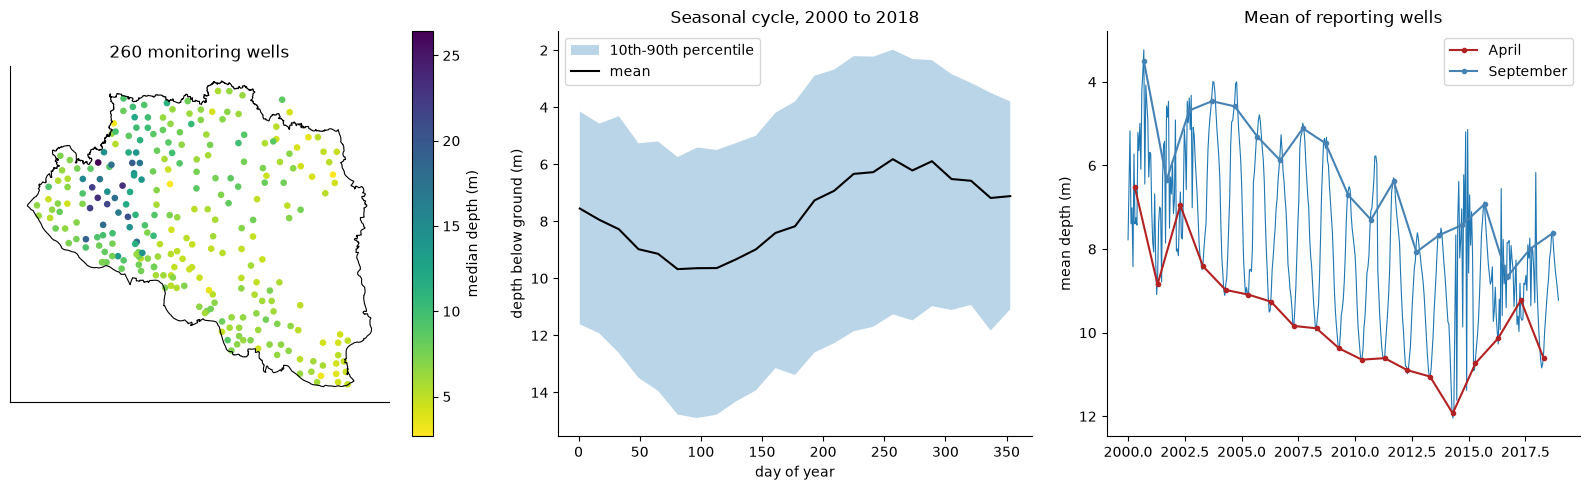

In [4]:
# Well locations coloured by median depth, the average seasonal cycle, and the 16-day mean through time.
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
aoi.boundary.plot(ax=ax[0], color="k", lw=0.8)
s = ax[0].scatter(wells.x, wells.y, c=wells.depth, s=14, cmap="viridis_r")
plt.colorbar(s, ax=ax[0], label="median depth (m)")
ax[0].set_title(f"{len(WID)} monitoring wells"); ax[0].set_aspect("equal"); ax[0].set_xticks([]); ax[0].set_yticks([])

# Day of year is the first day of each 16-day bin. The depth axis increases downward.
clim = gw.groupby("SixteenDayBin").Mean_WaterTable.agg(["mean", lambda s: s.quantile(0.1), lambda s: s.quantile(0.9)])
doy = 16 * (clim.index - 1) + 1
ax[1].fill_between(doy, clim.iloc[:, 1], clim.iloc[:, 2], alpha=0.3, label="10th-90th percentile")
ax[1].plot(doy, clim["mean"], "k-", label="mean")
ax[1].invert_yaxis(); ax[1].set_xlabel("day of year"); ax[1].set_ylabel("depth below ground (m)")
ax[1].set_title("Seasonal cycle, 2000 to 2018"); ax[1].legend()

mt = gw.groupby("t").Mean_WaterTable.mean()
ax[2].plot(2000 + mt.index / NPER, mt.values, lw=0.8)
ax[2].plot(by_year.index + 0.3, by_year.dry_Apr_depth, "o-", c="firebrick", ms=3, label="April")
ax[2].plot(by_year.index + 0.7, by_year.wet_Sep_depth, "o-", c="steelblue", ms=3, label="September")
ax[2].invert_yaxis(); ax[2].set_ylabel("mean depth (m)"); ax[2].legend(); ax[2].set_title("Mean of reporting wells")
plt.tight_layout(); plt.show()

**Reading the results.**

- **The panel holds 79,641 readings from 260 wells over 437 periods** (70% complete). Cleaning removed 10 readings out of range and 56 isolated spikes, and dropped 3 wells with fewer than 23 readings. 258 of the 260 wells are inside the division.
- **Wells are dense.** The median distance to the nearest well is 5.2 km, so most 1 km cells are within 3 km of a well.
- **Monitoring collapsed in 2016 and 2017.** Only 68 and 69 wells reported, against 202 to 255 in every other year. Maps for those two years rest on a third of the usual information.
- **The water table is falling.** The mean depth of reporting wells went from 5.8 m in 2000 to about 9 m after 2010. April (dry-season) depths went from 6.5 m to 10 to 12 m, and September (end of monsoon) depths from 3.5 m to 7 to 8 m. The September recovery therefore no longer brings the water table back to its 2000 level.
- **The seasonal cycle is about 4 m.** Water is deepest in April, at the end of the Boro irrigation season, and shallowest in September and October. The deepest wells (median depth over 15 m) are in the north-west, in the Barind Tract.

## Normal-score transform

Water table depths are skewed to the right: most wells sit at 3 to 10 m, but wells in the Barind Tract fall to 20 m and more in the dry season. Kriging gives the best linear estimate, and its variance turns into a prediction interval only for Gaussian data. The GSLIB normal-score transform (Deutsch and Journel, 1998) maps the ranked readings to standard normal quantiles. All wells and periods share one transform, so a score has the same meaning everywhere and at every time. After kriging, predictions are transformed back to metres (Section 6).

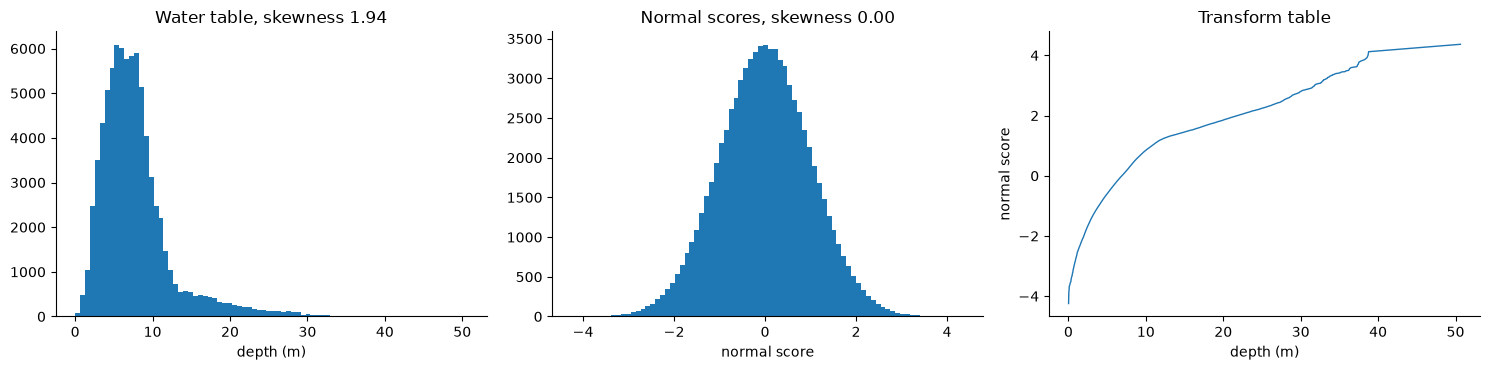

round trip error (m): 0.0


In [5]:
# Normal scores put the skewed depths on a Gaussian scale for the variogram and the kriging.
zs, vs, nss = nscore_forward(Z.ravel())
NS = zs.reshape(Z.shape)
obs = np.isfinite(Z)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(Z[obs], bins=80); ax[0].set_xlabel("depth (m)"); ax[0].set_title(f"Water table, skewness {pd.Series(Z[obs]).skew():.2f}")
ax[1].hist(NS[obs], bins=80); ax[1].set_xlabel("normal score"); ax[1].set_title(f"Normal scores, skewness {pd.Series(NS[obs]).skew():.2f}")
ax[2].plot(vs, nss, lw=1); ax[2].set_xlabel("depth (m)"); ax[2].set_ylabel("normal score"); ax[2].set_title("Transform table")
plt.tight_layout(); plt.show()
# Back-transform check. The recovered depths should match the originals to a small fraction of a metre.
print("round trip error (m):", np.nanmax(np.abs(nscore_back(NS[obs], vs, nss) - Z[obs])))

## Space-time variogram

The empirical space-time variogram compares every pair of readings with spatial distance h and time lag u (in 16-day periods):

γ(h, u) = 1 / (2 N(h, u)) Σ [z(s, t) − z(s + h, t + u)]²

The panel has gaps (wells start and stop, and only about 70 wells report in 2016 and 2017), so the estimator uses all pairs in which both readings exist. The first spatial bin holds h = 0, so that γ(0, u) measures how a well changes over u periods. Time lags up to 8 periods (128 days) are used for fitting.

The sum-metric model (Bilonick, 1988; Gräler et al., 2016) adds three structures:

γ(h, u) = γ_s(h) + γ_t(u) + γ_j(√(h² + (κu)²))

- γ_s, a spatial structure shared by all times (wells that are always deep or shallow);
- γ_t, a temporal structure shared by all places (the seasonal cycle and regional changes);
- γ_j, a joint structure in which κ (km per period) converts time into distance.

All three are exponential, and there is a spatial nugget. The total sill is held close to 1, the variance of normal scores. Without that constraint the model is not identified: with lags up to 128 days, the time structure can grow without bound. A Gaussian temporal structure fits slightly better, but it makes kriging systems with many consecutive readings from one well numerically singular, so the exponential is used.

The fit is weighted least squares with weights proportional to the number of pairs.

In [6]:
# Empirical variogram of the normal scores out to 90 km and 8 periods, including a bin at distance zero.
T_idx = np.arange(NT, dtype=float)
t0 = time.time()
emp = empirical_st_variogram(XY, T_idx, NS, n_space_bins=12, max_space_lag=90,
                             zero_distance_bin=True, max_time_lag=8)
emp = pd.DataFrame({k: np.asarray(emp[k], float) for k in ["dist", "timelag", "gamma", "np"]})
emp = emp[emp.np > 0].reset_index(drop=True)
print(f"{len(emp)} space-time bins in {time.time() - t0:.1f} s")


# Sum-metric model: a spatial nugget, spatial and temporal exponentials, and a joint exponential.
def gamma_sm(p, h, u):
    sn, sp, sr, tp, tr, jp, jr, ani = p
    return (sn * (h > 1e-6) + sp * (1 - np.exp(-h / sr)) + tp * (1 - np.exp(-u / tr))
            + jp * (1 - np.exp(-np.sqrt(h ** 2 + (ani * u) ** 2) / jr)))


# Bins with more pairs count more. The extra residual pulls the four sill terms toward a total of 1.
h, u, g, npair = emp.dist.values, emp.timelag.values, emp.gamma.values, emp.np.values
w_np = np.sqrt(npair / npair.sum())
fit = least_squares(lambda p: np.r_[w_np * (gamma_sm(p, h, u) - g), 3 * (p[[0, 1, 3, 5]].sum() - 1.0)],
                    [0.1, 0.3, 15, 0.3, 10, 0.2, 15, 1.0],
                    bounds=([0, 0, 2, 0, 1, 0, 1, 0.05], [1, 1, 150, 1, 200, 1, 150, 50]))
P = fit.x
names = ["spatial nugget", "spatial psill", "spatial range (km)", "temporal psill", "temporal range (periods)",
         "joint psill", "joint range (km)", "kappa (km per period)"]
print(pd.Series(P, index=names).round(3).to_string())
print(f"total sill {P[[0, 1, 3, 5]].sum():.3f}; weighted RMSE {np.sqrt(((w_np * (gamma_sm(P, h, u) - g)) ** 2).sum()):.4f}")
print("practical ranges (3 x range): space %.0f km, time %.0f days, joint %.0f km" % (3 * P[2], 3 * P[4] * 16, 3 * P[6]))

116 space-time bins in 0.0 s
spatial nugget               0.027
spatial psill                0.345
spatial range (km)          11.642
temporal psill               0.343
temporal range (periods)     5.451
joint psill                  0.285
joint range (km)            12.420
kappa (km per period)        1.621
total sill 1.000; weighted RMSE 0.0469
practical ranges (3 x range): space 35 km, time 262 days, joint 37 km


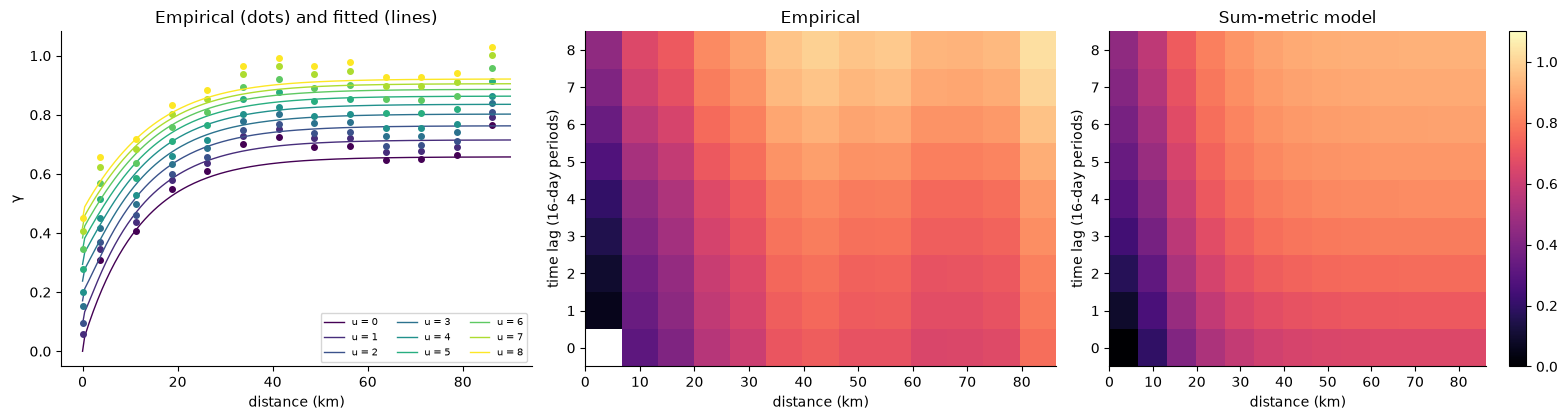

In [7]:
# Each time lag has its own colour. Lines are the fit and dots are the binned estimates.
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
cm = plt.cm.viridis(np.linspace(0, 1, 9))
hh = np.linspace(0, 90, 200)
for k in range(9):
    e = emp[emp.timelag == k]
    ax[0].plot(e.dist, e.gamma, "o", c=cm[k], ms=4)
    ax[0].plot(hh, gamma_sm(P, hh, k), "-", c=cm[k], lw=1, label=f"u = {k}")
ax[0].set_xlabel("distance (km)"); ax[0].set_ylabel("γ"); ax[0].legend(ncol=3, fontsize=7); ax[0].set_title("Empirical (dots) and fitted (lines)")
# The empirical surface and the fitted surface share one colour scale.
piv = emp.pivot_table(index="timelag", columns="dist", values="gamma")
for a, val, ttl in [(ax[1], piv.values, "Empirical"),
                    (ax[2], gamma_sm(P, piv.columns.values[None, :], piv.index.values[:, None]), "Sum-metric model")]:
    im = a.imshow(val, origin="lower", aspect="auto", cmap="magma", vmin=0, vmax=1.1,
                  extent=[piv.columns.min(), piv.columns.max(), -0.5, 8.5])
    a.set_xlabel("distance (km)"); a.set_ylabel("time lag (16-day periods)"); a.set_title(ttl)
plt.colorbar(im, ax=ax[2]); plt.tight_layout(); plt.show()

**The annual cycle beyond 128 days.** The model above stops at 8 periods. Extending the empirical variogram to two years shows what happens beyond that.

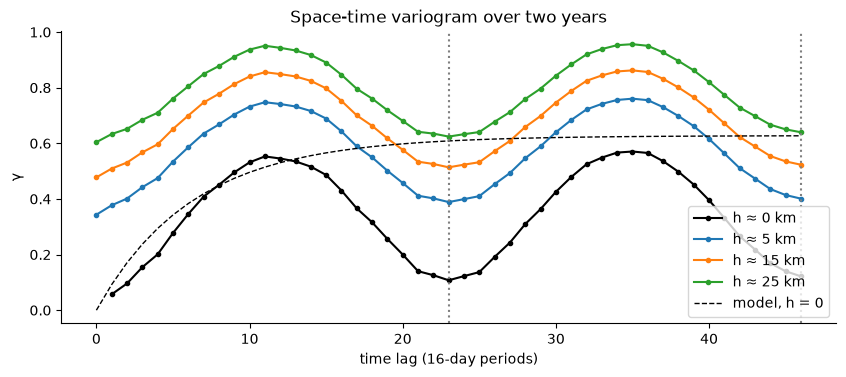

In [8]:
# Extend the empirical variogram across two years to show the annual cycle past the 8-period fit.
emp2 = empirical_st_variogram(XY, T_idx, NS, n_space_bins=6, max_space_lag=60, zero_distance_bin=True, max_time_lag=46)
emp2 = pd.DataFrame({k: np.asarray(emp2[k], float) for k in ["dist", "timelag", "gamma", "np"]})
fig, ax = plt.subplots(figsize=(10, 3.8))
for d0, c in zip(sorted(emp2.dist.unique())[:4], ["k", "C0", "C1", "C2"]):
    e = emp2[np.isclose(emp2.dist, d0)]
    ax.plot(e.timelag, e.gamma, "o-", ms=3, c=c, label=f"h ≈ {d0:.0f} km")
uu = np.arange(47)
ax.plot(uu, gamma_sm(P, 0, uu), "k--", lw=1, label="model, h = 0")
# One year and two years, counted in 16-day periods.
for x in [23, 46]:
    ax.axvline(x, c="grey", ls=":")
ax.set_xlabel("time lag (16-day periods)"); ax.set_ylabel("γ"); ax.legend(); ax.set_title("Space-time variogram over two years")
plt.show()

**Reading the results.**

- **Space.** The spatial structures have ranges of 11.6 km (pure space) and 12.4 km (joint), so practical ranges of about 35 km. The spatial nugget is only 0.03, so wells a few kilometres apart already differ, but not at random.
- **Time.** The temporal structure (psill 0.34, range 5.5 periods, practical range about 260 days) is the regional, shared part of the signal: the seasonal cycle and the year-to-year decline. At h = 0, γ rises from 0.06 at one period to about 0.5 at 10 to 12 periods.
- **Space-time anisotropy.** κ = 1.6 km per period: one 16-day step in time is worth 1.6 km in space for the joint structure. In the joint structure, a reading 64 days earlier at the same well counts as much as a reading today 6.4 km away.
- **The annual cycle.** Over two years, γ at h = 0 falls back to 0.11 at a lag of one year (23 periods) and rises again. A well is more like itself a year earlier than half a year earlier. The fitted model levels off at 0.63 and misses this cycle. That is harmless for kriging with a window of ±4 periods, but it means the previous year's readings are not used.

## Space-time kriging

For a target cell s₀ and period t₀, ordinary space-time kriging uses every reading within ±4 periods (±64 days) of t₀, about 1,000 to 1,400 readings. That is two thirds of the temporal practical range, so readings outside the window would get very small weights. With one window per period the kriging system is solved once and applied to all 18,224 cells of the 1 km grid:

- **Mean.** With covariance matrix K of the readings, k₀ the covariances between the target and the readings, and μ̂ the generalised least-squares mean, ẑ₀ = μ̂ + k₀ᵀ K⁻¹(z − μ̂1).
- **Variance.** σ²₀ = C(0) − k₀ᵀK⁻¹k₀ + (1 − 1ᵀK⁻¹k₀)² / (1ᵀK⁻¹1).

The spatial nugget is treated as micro-scale variation shared by all readings of a well, so it enters the covariance only for pairs at the same location, at any time lag.

Computing the variance costs one solve per target, so it is computed on a 4 km sub-grid and interpolated bilinearly to 1 km. The kriging variance depends only on the configuration of wells, which changes slowly in space. On a test period, the interpolated variance correlated with the exact one at 0.99, with the largest errors close to wells.

`geolattice.geostatistics.spacetime.STKriging` implements the same model with a moving k-nearest neighbourhood. Here the window solve is about 100 times faster, because it reuses one factorisation for all cells.

In [9]:
# Covariance form of the fitted sum-metric model. The nugget is present only at coincident wells.
def cov_sm(ds, dt, p=P):
    sn, sp, sr, tp, tr, jp, jr, ani = p
    return (sn * (ds < 1e-6) + sp * np.exp(-ds / sr) + tp * np.exp(-dt / tr)
            + jp * np.exp(-np.sqrt(ds * ds + (ani * dt) ** 2) / jr))


# Kriging variance is this sill minus the variance explained by the neighbours.
SILL = P[[0, 1, 3, 5]].sum()


def st_ok(DW, DT, wi, ti, z, tc, var_targets=None, jitter=1e-6):
    # Ordinary space-time kriging at period tc.
    # DW: well-to-well distance (km); DT: target-to-well distance (km)
    # wi, ti, z: well index, period and normal score of the readings in the window
    # var_targets: target-to-well distances where the variance is wanted (default: DT)
    K = cov_sm(DW[np.ix_(wi, wi)], np.abs(ti[:, None] - ti[None, :]).astype(float))
    K[np.diag_indices(len(z))] += jitter
    cf = cho_factor(K, lower=True)
    one = np.ones(len(z))
    Ki1 = cho_solve(cf, one); s1 = one @ Ki1
    mu = (Ki1 @ z) / s1
    res = cho_solve(cf, z - mu)
    dt = np.abs(tc - ti)[None, :].astype(float)
    pred = mu + cov_sm(DT[:, wi], dt) @ res
    Dv = DT if var_targets is None else var_targets
    k0 = cov_sm(Dv[:, wi], dt)
    q = np.einsum("ij,ji->i", k0, cho_solve(cf, k0.T))
    r = 1 - k0 @ Ki1
    return pred, np.clip(SILL - q + r * r / s1, 1e-6, None)


# Twenty-point Gauss-Hermite rule for the mean and SD after the back transform. 1.6449 is the normal 5% point.
GH_X, GH_W = np.polynomial.hermite_e.hermegauss(20)
GH_W = GH_W / GH_W.sum()
Q05, Q95 = -1.6449, 1.6449


def back_transform(m, v):
    # Gauss-Hermite mean and SD of the depth, and the 5th, 50th and 95th percentiles
    s = np.sqrt(v)
    y = nscore_back((m[:, None] + s[:, None] * GH_X[None, :]).ravel(), vs, nss).reshape(len(m), -1)
    y = np.clip(y, 0, None)
    mean = y @ GH_W
    sd = np.sqrt(np.clip((y * y) @ GH_W - mean ** 2, 0, None))
    qs = [np.clip(nscore_back(m + q * s, vs, nss), 0, None) for q in (Q05, 0.0, Q95)]
    return mean, sd, qs[0], qs[1], qs[2]


# A reading may enter the kriging system only if it falls within four periods, 64 days, of the target.
WIN = 4
oi, ot = np.nonzero(obs)            # well index and period of every reading
oz = NS[obs]

## Model validation: leaving wells out

Cross-validation that leaves single readings out would be too optimistic: a reading's own well, 16 days before and after, would nearly always be in the window. Here the 260 wells are split at random into five folds. Each fold is predicted at all its readings from the other 208 wells only, so every prediction is a genuine prediction at an unmonitored location. Two baselines show what space-time kriging adds:

- **IDW**: inverse-distance weighting (power 2) of the other wells in the same period, the usual way water table maps are made;
- **Climatology**: the mean of the other wells for the same 16-day period in the same year.

Metrics are computed in metres, after back-transformation:

- RMSE and MAE;
- NSE, the Nash-Sutcliffe efficiency, which is 1 minus the MSE divided by the variance of the observations;
- R², the squared Pearson correlation;
- the coverage of the 90% prediction interval.

In [10]:
# Error scores on the finite pairs: RMSE, NSE, percent bias, and the two relative errors.
def metrics(obs_, pred_):
    o, p = np.asarray(obs_, float), np.asarray(pred_, float)
    k = np.isfinite(o) & np.isfinite(p)
    o, p = o[k], p[k]
    e = p - o
    return {"n": len(o), "RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.mean(np.abs(e)),
            "NSE": 1 - np.sum(e ** 2) / np.sum((o - o.mean()) ** 2),
            "MARE": np.mean(np.abs(e) / np.abs(o)),
            "SMAPE": 100 * np.mean(2 * np.abs(e) / (np.abs(o) + np.abs(p))),
            "PBIAS": 100 * np.sum(e) / np.sum(o),
            "R2": np.corrcoef(o, p)[0, 1] ** 2}

In [11]:
# Five well folds. A held-out well is predicted only from other wells, and only from readings within the four-period window.
DW = cdist(XY, XY)
fold = RNG.permutation(np.arange(len(WID)) % 5)
cv = np.full((Z.size, 5), np.nan)          # mean, p05, p95, idw, climatology (flattened well x period)
t0 = time.time()
for f in range(5):
    test_w = np.flatnonzero(fold == f)
    trn = fold[oi] != f
    Dtw = DW[test_w]
    for tc in range(NT):
        tgt = test_w[obs[test_w, tc]]
        if len(tgt) == 0:
            continue
        m = trn & (np.abs(ot - tc) <= WIN)
        pr, va = st_ok(DW, DW[tgt], oi[m], ot[m], oz[m], tc)
        mean, sd, p05, p50, p95 = back_transform(pr, va)
        # Same-period baselines: inverse distance with power 2 (distances floored at 0.5 km) and the mean of those wells.
        cur = m & (ot == tc)
        idx = tgt * NT + tc
        cv[idx, 0], cv[idx, 1], cv[idx, 2] = mean, p05, p95
        if cur.sum() > 0:
            wz, wd = Z[oi[cur], tc], DW[np.ix_(tgt, oi[cur])]
            w_ = 1 / np.maximum(wd, 0.5) ** 2
            cv[idx, 3] = (w_ @ wz) / w_.sum(1)
            cv[idx, 4] = wz.mean()
print(f"cross-validation in {time.time() - t0:.0f} s")

# Compare the three predictors, and check how often the observed depth falls between the 5th and 95th percentiles.
zf = Z.ravel()
k = np.isfinite(zf)
cvt = pd.DataFrame({name: metrics(zf[k], cv[k, j]) for j, name in
                    [(0, "ST kriging"), (3, "IDW, same period"), (4, "Mean of other wells")]}).T
cvt["90% PI coverage"] = [np.mean((zf[k] >= cv[k, 1]) & (zf[k] <= cv[k, 2])), np.nan, np.nan]
cvt.round(3)

cross-validation in 233 s


,n,RMSE,MAE,NSE,MARE,SMAPE,PBIAS,R2,90% PI coverage
ST kriging,79641.0,2.998,1.986,0.585,0.334,26.161,0.016,0.586,0.861
"IDW, same period",79641.0,3.181,2.084,0.533,0.361,26.964,1.303,0.541,NaN
Mean of other wells,79641.0,4.301,2.850,0.145,0.496,36.375,-0.076,0.146,NaN


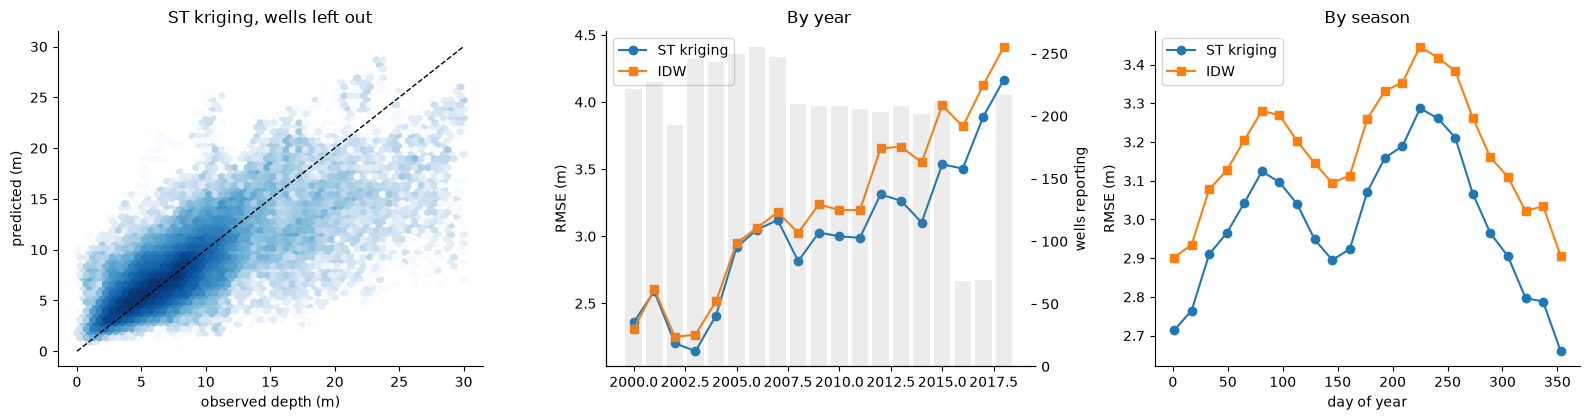

year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
wells,222.00,227.00,193.00,246.00,243.00,250.00,255.00,247.00,210.00,208.00,208.00,206.00,203.00,208.00,202.00,212.00,68.00,69.00,217.00
RMSE_stk,2.36,2.59,2.20,2.14,2.41,2.92,3.05,3.12,2.81,3.03,3.00,2.99,3.31,3.26,3.10,3.54,3.50,3.89,4.17
RMSE_idw,2.31,2.60,2.25,2.27,2.51,2.95,3.06,3.18,3.03,3.24,3.20,3.20,3.65,3.67,3.55,3.97,3.82,4.13,4.41
coverage,0.86,0.87,0.88,0.87,0.86,0.85,0.86,0.83,0.86,0.87,0.89,0.88,0.87,0.87,0.92,0.82,0.86,0.79,0.83


In [12]:
# Hold-out pairs, with the year and the 16-day bin attached for the summaries below.
cvd = pd.DataFrame({"well": np.repeat(np.arange(len(WID)), NT), "t": np.tile(np.arange(NT), len(WID)),
                    "obs": zf, "stk": cv[:, 0], "idw": cv[:, 3], "lo": cv[:, 1], "hi": cv[:, 2]}).dropna(subset=["obs", "stk"])
cvd["year"] = 2000 + cvd.t // NPER
cvd["bin"] = cvd.t % NPER + 1
yr = cvd.groupby("year").apply(lambda d: pd.Series({"wells": d.well.nunique(),
                                                    "RMSE_stk": np.sqrt(np.mean((d.stk - d.obs) ** 2)),
                                                    "RMSE_idw": np.sqrt(np.nanmean((d.idw - d.obs) ** 2)),
                                                    "coverage": np.mean((d.obs >= d.lo) & (d.obs <= d.hi))}))
# Scatter of predicted against observed depth, then RMSE by year and by season. The bars count wells reporting.
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
ax[0].hexbin(cvd.obs, cvd.stk, gridsize=60, bins="log", cmap="Blues", extent=(0, 30, 0, 30))
ax[0].plot([0, 30], [0, 30], "k--", lw=1); ax[0].set_xlabel("observed depth (m)"); ax[0].set_ylabel("predicted (m)")
ax[0].set_title("ST kriging, wells left out")
ax[1].plot(yr.index, yr.RMSE_stk, "o-", label="ST kriging"); ax[1].plot(yr.index, yr.RMSE_idw, "s-", label="IDW")
ax2 = ax[1].twinx(); ax2.bar(yr.index, yr.wells, alpha=0.15, color="grey"); ax2.set_ylabel("wells reporting")
ax[1].set_ylabel("RMSE (m)"); ax[1].legend(loc="upper left"); ax[1].set_title("By year")
sea = cvd.groupby("bin").apply(lambda d: pd.Series({"stk": np.sqrt(np.mean((d.stk - d.obs) ** 2)),
                                                   "idw": np.sqrt(np.nanmean((d.idw - d.obs) ** 2))}))
ax[2].plot(16 * (sea.index - 1) + 1, sea.stk, "o-", label="ST kriging"); ax[2].plot(16 * (sea.index - 1) + 1, sea.idw, "s-", label="IDW")
ax[2].set_xlabel("day of year"); ax[2].set_ylabel("RMSE (m)"); ax[2].legend(); ax[2].set_title("By season")
plt.tight_layout(); plt.show()
yr.round(2).T

**Reading the results.**

- **Space-time kriging is the most accurate of the three methods, but not by much.** At wells left out, its RMSE is 3.00 m, MAE 1.99 m, NSE 0.59 and R² 0.59. IDW in the same period has an RMSE of 3.18 m and NSE 0.53, and the mean of the other wells 4.30 m and NSE 0.15.
- **Most of the error is local.** Wells 5 km apart often differ by several metres, especially in the Barind Tract, where depths of 20 to 30 m are under-predicted. No interpolator can recover a well that is unlike its neighbours. The gain from time comes from neighbours' readings in adjacent periods, which matters most when a neighbour has not reported in the target period.
- **The intervals are slightly too narrow.** The 90% prediction interval covers 86% of the readings left out (79% in 2017). Its width comes from one stationary variogram, which is too small for the deep, variable wells.
- **Accuracy falls over time, as the water table becomes more variable.** RMSE grows from 2.2 to 2.6 m in 2000 to 2004 to 3.5 to 4.2 m after 2015. Its advantage over IDW grows from almost nothing before 2005 to 0.3 to 0.5 m after 2010, when wells report less regularly and neighbours' readings from adjacent periods fill the gaps.
- **Errors peak twice a year**: in April, when irrigation pumping is uneven, and in August, when recharge is.

## Prediction on the 1 km grid, 2000 to 2018

The 1 km grid is aligned to whole kilometres in BUTM 2010 and covers the AOI: 164 rows × 185 columns, origin (298,000 E, 2,797,000 N), with 18,224 cells inside the division boundary. Part 2 uses the same grid. For every period the kriged normal-score mean and variance are transformed back with a 20-point Gauss-Hermite rule:

E[Y] = ∫ φ⁻¹(m + s x) φ(x) dx

The rule gives the mean and standard deviation of the depth; the percentiles are φ⁻¹(m + z_q s). Here φ⁻¹ is the inverse normal-score transform, with linear extrapolation beyond the observed range. Each period is written as `wt_{YYYY}_{DDD}.tif` (DDD = first Julian day of the period, as in the input files) with five bands: mean, SD, P05, median and P95, in metres below ground. Cells outside the AOI are NaN.

In [13]:
# 1 km cells over the division. The kriging variance is solved on a 4 km lattice and interpolated back to 1 km.
b = aoi.total_bounds
GX0, GY1 = np.floor(b[0] / 1000) * 1000, np.ceil(b[3] / 1000) * 1000
GW, GH = int(np.ceil((b[2] - GX0) / 1000)), int(np.ceil((GY1 - b[1]) / 1000))
GTR = from_origin(GX0, GY1, 1000, 1000)
INSIDE = ~geometry_mask(aoi.geometry, (GH, GW), GTR)
rr, cc = np.nonzero(INSIDE)
G = np.c_[(GX0 + (cc + 0.5) * 1000) / 1000, (GY1 - (rr + 0.5) * 1000) / 1000]
DG = cdist(G, XY)
cx = np.arange(GX0 / 1000 + 2, GX0 / 1000 + GW + 4, 4.0)
cy = np.arange(GY1 / 1000 - 2, GY1 / 1000 - GH - 4, -4.0)
CXg, CYg = np.meshgrid(cx, cy)
DGc = cdist(np.c_[CXg.ravel(), CYg.ravel()], XY)
print(f"grid {GH} x {GW}, {INSIDE.sum()} cells in the AOI, variance sub-grid {CXg.size} cells")

# Five bands, in metres below ground: mean, standard deviation, 5th percentile, median, and 95th percentile.
profile = dict(driver="GTiff", height=GH, width=GW, count=5, dtype="float32", crs=CRS, transform=GTR,
               nodata=np.nan, compress="deflate", predictor=3, tiled=False)
BANDS = ["mean", "sd", "p05", "median", "p95"]
AOI_MEAN = np.zeros((NT, 5))
t0 = time.time()
# Kriging at every 16-day period, written as one GeoTIFF named by year and the first day of the bin.
for tc in range(NT):
    m = np.abs(ot - tc) <= WIN
    pr, vc = st_ok(DW, DG, oi[m], ot[m], oz[m], tc, var_targets=DGc)
    va = RegularGridInterpolator((cy[::-1], cx), vc.reshape(CXg.shape)[::-1], bounds_error=False,
                                 fill_value=None)(G[:, ::-1])
    out = back_transform(pr, np.clip(va, 1e-6, None))
    arr = np.full((5, GH, GW), np.nan, np.float32)
    for j in range(5):
        arr[j][INSIDE] = out[j]
    AOI_MEAN[tc] = [np.mean(o) for o in out]
    yy, bb = 2000 + tc // NPER, tc % NPER
    with rasterio.open(OUT_WT / f"wt_{yy}_{16 * bb + 1:03d}.tif", "w", **profile) as dst:
        dst.write(arr)
        dst.descriptions = tuple(BANDS)
        dst.update_tags(units="m below ground", method="space-time ordinary kriging of normal scores",
                        period=f"{yy} 16-day period {bb + 1}")
print(f"{NT} GeoTIFFs written to {OUT_WT.relative_to(ROOT)} in {time.time() - t0:.0f} s")
print(sorted(os.listdir(OUT_WT))[:3], "...", sorted(os.listdir(OUT_WT))[-1])

grid 164 x 185, 18224 cells in the AOI, variance sub-grid 1974 cells


437 GeoTIFFs written to Data/00_shared/data_geostatistics/BD_Raj/RAJ_Raster/Water_table in 445 s
['wt_2000_001.tif', 'wt_2000_017.tif', 'wt_2000_033.tif'] ... wt_2018_353.tif


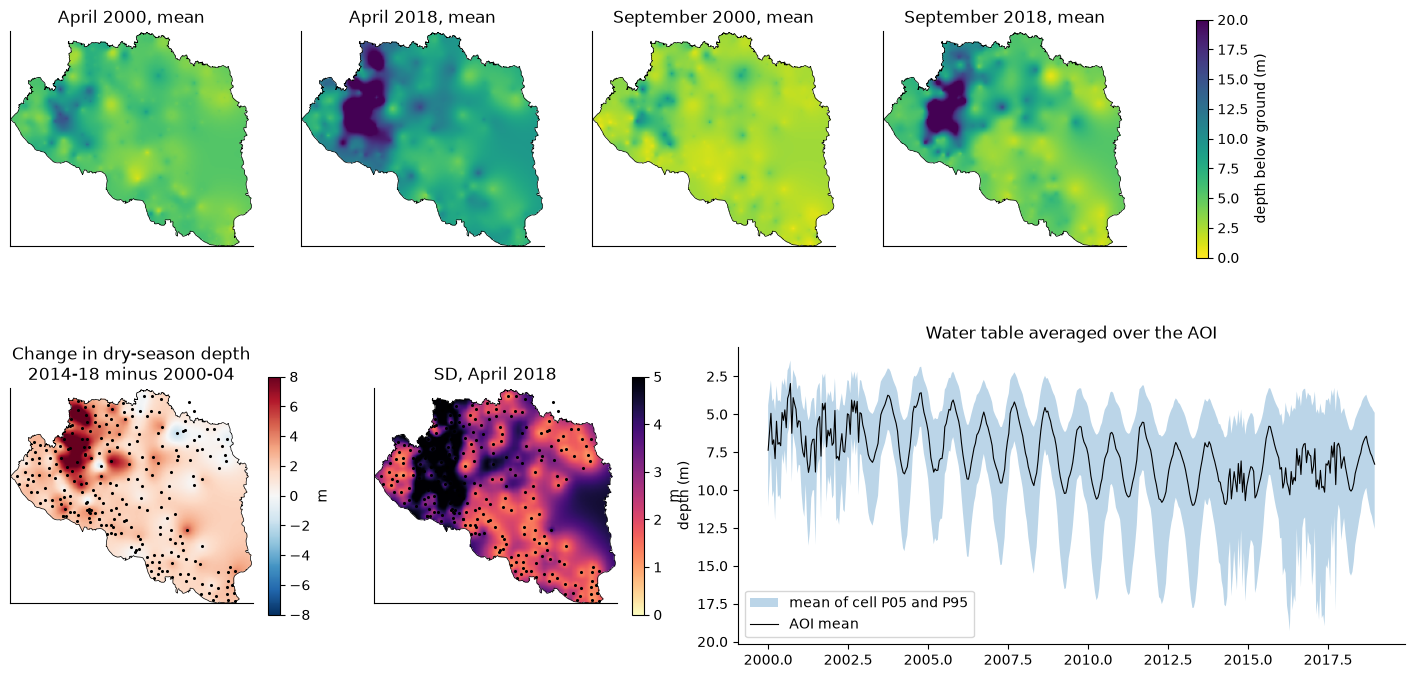

AOI mean change in dry-season depth: +2.21 m; cells deeper by more than 3 m: 17%


In [14]:
# Open one water-table GeoTIFF. Band 1 is the mean depth and band 2 is the standard deviation.
def read_wt(year, doy, band=1):
    with rasterio.open(OUT_WT / f"wt_{year}_{doy:03d}.tif") as s:
        return s.read(band)


# April and September at the start and end of the record.
ext = [GX0, GX0 + GW * 1000, GY1 - GH * 1000, GY1]
fig, ax = plt.subplots(2, 4, figsize=(18, 8.5))
for j, (yy, dd, lab) in enumerate([(2000, 97, "April 2000"), (2018, 97, "April 2018"),
                                    (2000, 257, "September 2000"), (2018, 257, "September 2018")]):
    a = ax[0, j]
    im = a.imshow(read_wt(yy, dd), extent=ext, cmap="viridis_r", vmin=0, vmax=20)
    aoi.boundary.plot(ax=a, color="k", lw=0.5); a.set_title(lab + ", mean"); a.set_xticks([]); a.set_yticks([])
plt.colorbar(im, ax=ax[0, :], shrink=0.8, label="depth below ground (m)")
# Dry-season depth averages DOY 81, 97, and 113. The change map is 2014-2018 minus 2000-2004.
dry = lambda y0, y1: np.nanmean([read_wt(y, d) for y in range(y0, y1 + 1) for d in (81, 97, 113)], axis=0)
change = dry(2014, 2018) - dry(2000, 2004)
im = ax[1, 0].imshow(change, extent=ext, cmap="RdBu_r", vmin=-8, vmax=8)
plt.colorbar(im, ax=ax[1, 0], shrink=0.8, label="m")
ax[1, 0].set_title("Change in dry-season depth\n2014-18 minus 2000-04")
im = ax[1, 1].imshow(read_wt(2018, 97, 2), extent=ext, cmap="magma_r", vmin=0, vmax=5)
plt.colorbar(im, ax=ax[1, 1], shrink=0.8, label="m"); ax[1, 1].set_title("SD, April 2018")
for a in ax[1, :2]:
    aoi.boundary.plot(ax=a, color="k", lw=0.5); a.scatter(wells.x, wells.y, s=1.5, c="k"); a.set_xticks([]); a.set_yticks([])
# Mean depth over the division through all 437 periods, with the band between the cell 5th and 95th percentiles.
gs = ax[1, 2].get_gridspec()
for a in ax[1, 2:]:
    a.remove()
axb = fig.add_subplot(gs[1, 2:])
yrs = 2000 + np.arange(NT) / NPER
axb.fill_between(yrs, AOI_MEAN[:, 2], AOI_MEAN[:, 4], alpha=0.3, label="mean of cell P05 and P95")
axb.plot(yrs, AOI_MEAN[:, 0], "k-", lw=0.8, label="AOI mean")
axb.invert_yaxis(); axb.set_ylabel("depth (m)"); axb.legend(); axb.set_title("Water table averaged over the AOI")
plt.show()
print(f"AOI mean change in dry-season depth: {np.nanmean(change):+.2f} m; "
      f"cells deeper by more than 3 m: {np.mean(change[INSIDE] > 3):.0%}")

**Reading the results.**

- **437 GeoTIFFs** (`wt_2000_001.tif` to `wt_2018_353.tif`, five bands each) are in `RAJ_Raster/Water_table`. Writing them took about 15 minutes.
- **The decline is concentrated in the north-west.** Between 2000 to 2004 and 2014 to 2018, the dry-season water table fell by 2.2 m on average over the AOI, and by more than 3 m in 17% of cells. The largest falls, 6 to 8 m, are in the Barind Tract (Rajshahi, Naogaon and Chapai Nawabganj districts), where April depths now exceed 20 m. In the south and east the change is small.
- **Uncertainty follows the wells and the depth.** The SD is under 1 m next to wells and reaches 5 m in the deep north-west, where the back-transformed distribution has a long tail.
- **The AOI mean series is smooth except in 2016 and 2017**, when the 68 to 69 reporting wells changed from period to period and the mean jumps. Those two years should be read as less reliable.

# Part 2: Spatio-temporal forecasting with deep learning

The 1 km water table maps from Part 1 become the response of three forecasting models. Each model sees the last L periods of all channels, the water table and its covariates, and predicts the water table one period (16 days) ahead. For 2018 the models run recursively: each forecast is fed back as the water-table input of the next step, so the 2018 forecast uses no groundwater data from 2018.

| Model | Space | Time |
|---|---|---|
| CNN-LSTM (baseline) | two 3×3 convolutions per period | LSTM over the L periods, per pixel |
| ST-GNN | two graph convolutions on the 8-neighbour pixel graph | GRU per node |
| ST-GTN | multi-head attention over each node's 8 neighbours (graph transformer) | temporal self-attention per node |

All three predict the change from the last observed water table, so a model that learns nothing reproduces persistence. That makes persistence the baseline that matters.

## Covariates and the common 1 km grid

| Source | Variables | Native grid | Resampling to 1 km |
|---|---|---|---|
| ERA-Interim (16-day) | t2m, mn2t, mx2t (2 m temperature, min, max), tp (precipitation), ssr, str (net short- and long-wave radiation), e (evaporation), slhf (latent heat flux), ro (runoff) | BUTM 2010, ~1001 m, 164 × 184 | bilinear |
| MODIS MOD13Q1 | NDVI (scale 10⁻⁴, 16-day) | BUTM 2010, ~999 m, 164 × 184 | bilinear |
| GlobPOP | population per cell, annual | BUTM 2010, ~999 m | bilinear, log(1 + x) |
| HILDA+ v2b | land-use class, annual | WGS 84, 0.01° | nearest, then 6 one-hot channels |
| SRTM DEM | elevation | BUTM 2010, ~250 m | average |

The climate and NDVI rasters are close to the common grid but not on it: their cells are 999 to 1001 m and their origins are 521 m east of a whole kilometre. Every source is therefore reprojected with `rasterio.warp.reproject` to the Part 1 grid, 164 × 185 cells of exactly 1 km.

The HILDA+ codes are grouped as urban (11), cropland (20 to 29), grassland and pasture (33, 55), forest (40 to 49), water (77) and other. Missing climate periods (DOY 337 and 353 of 2011) are filled by linear interpolation in time, pixel by pixel.

**Run mode.** The full forecasting run needs about 2,100 covariate files for 2010 to 2018. If they are not all present, the notebook writes synthetic covariates with the same file names, grids, data types and gaps to a temporary folder and runs every step on them. Those results test the pipeline and are not forecasts: the synthetic covariates carry no information about groundwater. The outputs printed below say which mode was used.

In [15]:
# Covariates expected for 2010-2018. The forecast half uses the real rasters only when each variable is at least 95% complete.
import tempfile
from rasterio.warp import reproject, Resampling

CLIM_VARS = ["t2m", "mn2t", "mx2t", "tp", "ssr", "str", "e", "slhf", "ro"]
Y2 = np.arange(2010, 2019)
T2 = len(Y2) * NPER                       # 207 periods, 2010-2018
DOYS = 16 * np.arange(NPER) + 1
TIMES2 = [(int(y), int(d)) for y in Y2 for d in DOYS]


# File names follow the archive: climate and NDVI by year and day, population and land use by year.
def cov_paths(src):
    p = {v: [src / "Climate_data" / v / f"{v}_{y}_{d:03d}.tif" for y, d in TIMES2] for v in CLIM_VARS}
    p["ndvi"] = [src / "NDVI" / str(y) / f"ndvi_{y}_{d}.tif" for y, d in TIMES2]
    p["pop"] = [src / "Population" / f"population_{y}.tif" for y in Y2]
    p["landuse"] = [src / "Landuse" / f"landuse_{y}.tif" for y in Y2]
    return p


# FULL_RUN is the switch between the real archive and a synthetic pipeline check.
avail = pd.Series({k: np.mean([f.is_file() for f in v]) for k, v in cov_paths(RASTER).items()})
FULL_RUN = bool((avail >= 0.95).all())
print("share of expected covariate files present in", RASTER.relative_to(ROOT))
print(avail.round(3).to_string())
print("\nRUN MODE:", "FULL (real covariates)" if FULL_RUN else "PIPELINE CHECK (synthetic covariates; results are not forecasts)")

share of expected covariate files present in Data/00_shared/data_geostatistics/BD_Raj/RAJ_Raster
t2m        0.99
mn2t       0.99
mx2t       0.99
tp         0.99
ssr        0.99
str        0.99
e          0.99
slhf       0.99
ro         0.99
ndvi       1.00
pop        1.00
landuse    1.00

RUN MODE: FULL (real covariates)


In [16]:
def write_synthetic_covariates(dst):
    # Synthetic rasters with the real names, grids, dtypes and gaps (for the pipeline check only)
    rng = np.random.default_rng(1)
    clim_tr = from_origin(298521.659, 2796723.768, 1001.1476, 1001.1476)
    ndvi_tr = from_origin(298521.659, 2796947.963, 999.0618, 999.0618)
    lu_tr = from_origin(88.01, 25.27, 0.01, 0.01)
    yy, xx = np.mgrid[0:164, 0:184] / 184.0

    def w(path, arr, tr, crs, nodata):
        path.parent.mkdir(parents=True, exist_ok=True)
        with rasterio.open(path, "w", driver="GTiff", height=arr.shape[0], width=arr.shape[1], count=1,
                           dtype=arr.dtype, crs=crs, transform=tr, nodata=nodata) as s:
            s.write(arr, 1)

    # Seasonal cycle plus a weak west-east ramp, in the units of the real climate files.
    base = {"t2m": (298, 6), "mn2t": (292, 6), "mx2t": (305, 6), "tp": (3, 2), "ssr": (1.5e7, 4e6),
            "str": (-6e6, 1e6), "e": (-0.3, 0.1), "slhf": (-2e6, 6e5), "ro": (0.05, 0.03)}
    for v, (mu, amp) in base.items():
        for (y, d), f in zip(TIMES2, cov_paths(dst)[v]):
            if y == 2011 and d in (337, 353):
                continue                                   # same gap as the real archive
            a = mu + amp * (np.sin(2 * np.pi * (d - 80) / 365) + 0.3 * xx) + 0.1 * amp * rng.standard_normal((164, 184))
            w(f, a.astype("float64"), clim_tr, CRS, np.nan)
    for (y, d), f in zip(TIMES2, cov_paths(dst)["ndvi"]):
        a = 4000 + 2500 * np.sin(2 * np.pi * (d - 200) / 365) * (0.6 + yy) + 300 * rng.standard_normal((164, 184))
        w(f, a.astype("int16"), ndvi_tr, CRS, -32768)
    for y, f in zip(Y2, cov_paths(dst)["pop"]):
        w(f, (rng.lognormal(6, 1, (164, 184)) * (1 + 0.01 * (y - 2010))).astype("float32"), ndvi_tr, CRS, np.nan)
    # Land-cover codes on the geographic grid used by the real land-use files.
    codes = np.array([11, 22, 23, 24, 33, 40, 55, 66, 77], np.uint8)
    for y, f in zip(Y2, cov_paths(dst)["landuse"]):
        w(f, rng.choice(codes, (146, 181), p=[.02, .55, .2, .05, .04, .02, .02, .03, .07]), lu_tr, "EPSG:4326", 255)


# Keep the real directory when the archive is complete. Otherwise write a temporary stand-in and continue.
if FULL_RUN:
    SRC = RASTER
else:
    SRC = Path(tempfile.mkdtemp(prefix="raj_synthetic_"))
    t0 = time.time(); write_synthetic_covariates(SRC)
    print(f"synthetic covariates written to {SRC} in {time.time() - t0:.0f} s")
PATHS = cov_paths(SRC)

## GeoTIFF cubes and a Dask T × C × H × W array

Each variable is reprojected to the 1 km grid and written as one multi-band GeoTIFF with one band per period (207 bands for 2010 to 2018) in `RAJ_Raster/Cube_1km/`. Annual layers (population, land use) and the DEM are repeated over the periods of their year. The water-table cube comes from band 1 (mean) of the Part 1 GeoTIFFs.

The cubes are opened lazily as a Dask array of shape T × C × H × W with one chunk per year and variable. The normalisation statistics are computed from that array before it is loaded into memory for training.

In [17]:
# Warp every covariate onto the 1 km water-table grid and store 2010-2018 as a time cube.
import dask
import dask.array as da

CUBE = RASTER / "Cube_1km" if FULL_RUN else SRC / "Cube_1km"
CUBE.mkdir(parents=True, exist_ok=True)


# Bilinear warp into the kriging grid. Sentinel nodata values are cleared before resampling.
def to_grid(path, resampling=Resampling.bilinear, scale=1.0):
    with rasterio.open(path) as s:
        src = s.read(1).astype("float64")
        if s.nodata is not None and not np.isnan(s.nodata):
            src[src == s.nodata] = np.nan
        out = np.full((GH, GW), np.nan)
        reproject(src, out, src_transform=s.transform, src_crs=s.crs, dst_transform=GTR, dst_crs=CRS,
                  resampling=resampling, src_nodata=np.nan, dst_nodata=np.nan)
    return (out * scale).astype("float32")


def fill_time(cube):
    # Linear interpolation in time for missing layers (and isolated missing pixels)
    T_, H_, W_ = cube.shape
    flat = cube.reshape(T_, -1)
    tt = np.arange(T_)
    for j in np.flatnonzero(np.isnan(flat).any(0) & np.isfinite(flat).any(0)):
        k = np.isfinite(flat[:, j])
        flat[~k, j] = np.interp(tt[~k], tt[k], flat[k, j])
    return flat.reshape(T_, H_, W_)


# One GeoTIFF per variable, with one band per 16-day period.
def write_cube(name, arr):
    prof = dict(driver="GTiff", height=GH, width=GW, count=arr.shape[0], dtype="float32", crs=CRS,
                transform=GTR, nodata=np.nan, compress="deflate", predictor=3)
    with rasterio.open(CUBE / f"{name}_2010_2018.tif", "w", **prof) as d:
        d.write(arr.astype("float32"))


# Fill missing climate and NDVI periods in time. NDVI integers are scaled by 1e-4 back to the fractional index.
t0 = time.time()
gap_count = {}
for v in CLIM_VARS + ["ndvi"]:
    sc = 1e-4 if v == "ndvi" else 1.0
    arr = np.stack([to_grid(f, scale=sc) if f.is_file() else np.full((GH, GW), np.nan, "float32") for f in PATHS[v]])
    gap_count[v] = int(sum(not f.is_file() for f in PATHS[v]))
    write_cube(v, fill_time(arr))
# Annual layers are repeated across the 23 periods of their year. Population is stored as log(1 + count).
rep = np.repeat(np.arange(len(Y2)), NPER)
pop = np.stack([to_grid(f) for f in PATHS["pop"]])
write_cube("pop", np.log1p(np.clip(pop, 0, None))[rep])
lu = np.stack([to_grid(f, Resampling.nearest) for f in PATHS["landuse"]])
# One-hot land cover. Codes outside these groups become the other-land class.
LU_GROUPS = {"urban": [11], "cropland": list(range(20, 30)), "grass": [33, 55],
             "forest": list(range(40, 50)), "water": [77]}
lu_known = np.zeros_like(lu, bool)
for k, codes in LU_GROUPS.items():
    m = np.isin(lu, codes); lu_known |= m
    write_cube(f"lu_{k}", m.astype("float32")[rep])
write_cube("lu_other", (~lu_known & np.isfinite(lu)).astype("float32")[rep])
# Elevation does not change with time. The kriged water table is copied in as the target channel.
dem = to_grid(RASTER / "raj_DEM_BUTM.tif", Resampling.average)
write_cube("dem", np.repeat(dem[None], T2, 0))
wt = np.stack([read_wt(y, d) for y, d in TIMES2])
write_cube("wt", wt)
print(f"cubes written to {CUBE} in {time.time() - t0:.0f} s; missing periods filled: {gap_count}")

cubes written to /home/zia207/Github/GeoLattice/Data/00_shared/data_geostatistics/BD_Raj/RAJ_Raster/Cube_1km in 17 s; missing periods filled: {'t2m': 2, 'mn2t': 2, 'mx2t': 2, 'tp': 2, 'ssr': 2, 'str': 2, 'e': 2, 'slhf': 2, 'ro': 2, 'ndvi': 0}


In [18]:
# Channel order for the lazy cube. The water table stays in position 0 because the models treat it as the target.
CHANNELS = (["wt"] + CLIM_VARS + ["ndvi", "pop", "dem"] + [f"lu_{k}" for k in LU_GROUPS] + ["lu_other"])


# Each year is a delayed read, so building the stack does not load the cubes yet.
def lazy_cube(name):
    path = CUBE / f"{name}_2010_2018.tif"
    def read_year(i):
        with rasterio.open(path) as s:
            return s.read(list(range(i * NPER + 1, (i + 1) * NPER + 1)))
    return da.concatenate([da.from_delayed(dask.delayed(read_year)(i), (NPER, GH, GW), "float32")
                           for i in range(len(Y2))], axis=0)


# Sine and cosine of the day of year, plus a mask that is 1 inside the division.
doy = np.array([d for _, d in TIMES2])
seas = np.stack([np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)], 1).astype("float32")
X = da.stack([lazy_cube(c) for c in CHANNELS]
             + [da.from_array(np.broadcast_to(seas[:, j, None, None], (T2, GH, GW)), chunks=(NPER, GH, GW)) for j in range(2)]
             + [da.from_array(np.broadcast_to(INSIDE.astype("float32"), (T2, GH, GW)), chunks=(NPER, GH, GW))], axis=1)
CHANNELS = CHANNELS + ["doy_sin", "doy_cos", "aoi"]
print("Dask array", X.shape, X.dtype, "chunks", X.chunksize, f"{X.nbytes / 1e9:.2f} GB")
X

Dask array (207, 22, 164, 185) float32 chunks (23, 1, 164, 185) 0.55 GB


dask.array<stack, shape=(207, 22, 164, 185), dtype=float32, chunksize=(23, 1, 164, 185), chunktype=numpy.ndarray>

## Normalisation, splits, patches and the pixel graph

**Normalisation.** Each channel is standardised with the mean and SD of the training periods (2010 to 2014) over the AOI cells only, so no information from validation or test years enters the inputs. Cells outside the AOI and remaining gaps are set to 0 after standardisation, and the `aoi` channel tells the models which cells are real.

**Splits by target period.**

| Split | Target periods | Use |
|---|---|---|
| Training | 2010 to 2014 (after the first L periods) | fitting |
| Validation | 2015 to 2016 | Optuna objective, early stopping, model selection; monthly and seasonal scores |
| Testing | 2017 | one-step-ahead accuracy, by period, month and season |
| Forecasting | 2018 | recursive 23-step forecast, by period, month and season |

**Patches.** The 164 × 185 grid is cut into 64 × 64 patches with a stride of 32 (the last row and column of patches are shifted to end at the grid edge). Patches with less than 5% of their cells in the AOI are skipped. Overlapping predictions are averaged when patches are put back together.

**Graph.** Each patch is a graph of 4,096 nodes (pixels). Every pixel is joined to its 8 neighbours, which gives a sparse adjacency matrix A. The ST-GNN uses the normalised Â = D^(-1/2) (A + I) D^(-1/2) (Kipf and Welling, 2017), and the ST-GTN uses the neighbour lists to restrict attention. All patches share the same graph. The AOI mask decides which nodes count in the loss.

         wt        t2m       mn2t    mx2t     tp         ssr           str      e         slhf     ro   ndvi    pop        dem  lu_urban  lu_cropland  lu_grass  lu_forest  lu_water  lu_other  doy_sin  doy_cos  aoi
mean  8.705  24.952999  24.049999  25.961  1.500  4992519.00 -1.550975e+06 -1.106 -2765461.750  0.643  0.463  6.799  18.344999       0.0          0.0       0.0        0.0       0.0       0.0      0.0      0.0  0.0
sd    3.783   4.503000   4.784000   4.258  1.615   945626.25  6.216367e+05  0.297   741656.375  0.932  0.180  0.703   6.473000       1.0          1.0       1.0        1.0       1.0       1.0      1.0      1.0  1.0


normalised cube (207, 22, 164, 185), 0.55 GB in memory, built in 1 s
24 patches of 64 x 64 (stride 32)
graph: 4096 nodes, 32004 directed edges, degree 3 to 8


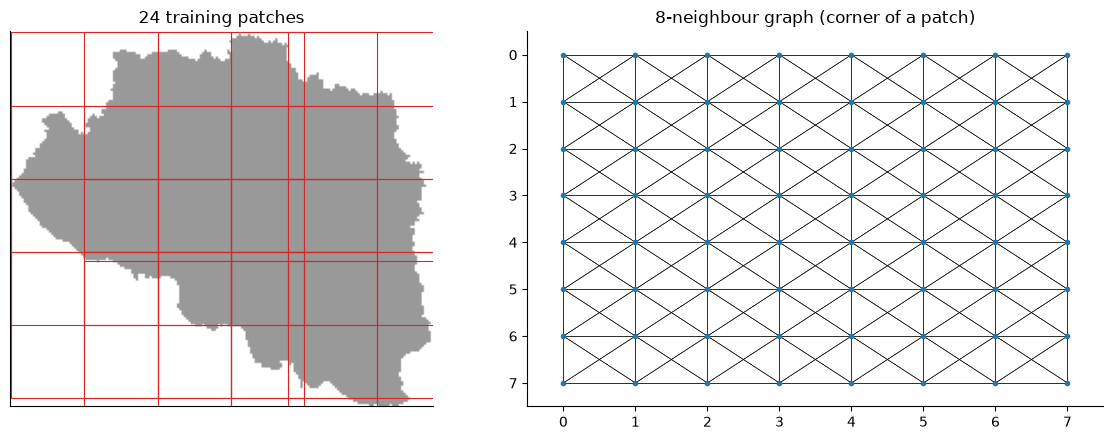

In [19]:
# Channel mean and standard deviation from 2010-2014 pixels inside the division.
import torch
warnings.filterwarnings("ignore", message="Sparse invariant")

tr_t = np.array([i for i, (y, _) in enumerate(TIMES2) if y <= 2014])
inside_flat = INSIDE.ravel()
Xs = X[tr_t].reshape(len(tr_t), len(CHANNELS), -1)[:, :, inside_flat]
mu_c, sd_c = dask.compute(da.nanmean(Xs, axis=(0, 2)), da.nanstd(Xs, axis=(0, 2)))
sd_c = np.where(sd_c > 1e-8, sd_c, 1.0)
for c in ["doy_sin", "doy_cos", "aoi"] + [f"lu_{k}" for k in LU_GROUPS] + ["lu_other"]:
    j = CHANNELS.index(c); mu_c[j], sd_c[j] = 0.0, 1.0       # keep indicators and seasonal terms as they are
print(pd.DataFrame({"mean": mu_c, "sd": sd_c}, index=CHANNELS).round(3).T.to_string())

# Materialise the standardised cube. Non-finite values, and pixels outside the division, are set to zero.
t0 = time.time()
XN = ((X - mu_c[None, :, None, None]) / sd_c[None, :, None, None]).compute().astype("float32")
XN[~np.isfinite(XN)] = 0.0
XN[:, :, ~INSIDE] = 0.0
XN[:, CHANNELS.index("aoi")] = INSIDE
WT_MU, WT_SD = float(mu_c[0]), float(sd_c[0])
WT_TRUE = np.where(INSIDE, wt, np.nan)            # kriged water table (m), T2 x H x W
print(f"normalised cube {XN.shape}, {XN.nbytes / 1e9:.2f} GB in memory, built in {time.time() - t0:.0f} s")

# Overlapping 64 by 64 patches, stride 32. A patch is kept only when at least 5% of it lies inside the division.
PS, STRIDE = 64, 32
def starts(n):
    s = list(range(0, n - PS + 1, STRIDE))
    return s if s[-1] == n - PS else s + [n - PS]
PATCHES = [(r, c) for r in starts(GH) for c in starts(GW) if INSIDE[r:r + PS, c:c + PS].mean() >= 0.05]
print(f"{len(PATCHES)} patches of {PS} x {PS} (stride {STRIDE})")

# 8-neighbour graph of a 64 x 64 patch
ii_, jj_ = np.mgrid[0:PS, 0:PS]
node = (ii_ * PS + jj_).ravel()
src, dst = [], []
NBR = np.tile(node[:, None], (1, 9))            # self + 8 neighbours (self repeated where a neighbour is missing)
NBR_OK = np.zeros((PS * PS, 9), bool); NBR_OK[:, 0] = True
k = 1
for di in (-1, 0, 1):
    for dj in (-1, 0, 1):
        if di == 0 and dj == 0:
            continue
        ok_ = ((ii_ + di >= 0) & (ii_ + di < PS) & (jj_ + dj >= 0) & (jj_ + dj < PS)).ravel()
        nb = ((ii_ + di) * PS + (jj_ + dj)).ravel()
        src.append(node[ok_]); dst.append(nb[ok_])
        NBR[ok_, k] = nb[ok_]; NBR_OK[ok_, k] = True; k += 1
src, dst = np.concatenate(src), np.concatenate(dst)
# Symmetric normalisation of the adjacency, including a self-loop, as used by the graph convolution.
deg = np.bincount(src, minlength=PS * PS) + 1.0
rows = np.r_[src, node]; cols = np.r_[dst, node]
vals = 1 / np.sqrt(deg[rows] * deg[cols])
A_HAT = torch.sparse_coo_tensor(np.vstack([rows, cols]), vals.astype("float32"), (PS * PS, PS * PS)).coalesce()
print(f"graph: {PS * PS} nodes, {len(src)} directed edges, degree {np.bincount(src).min()} to {np.bincount(src).max()}")

# Where the patches sit on the division, and the neighbour edges in one corner of a patch.
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].imshow(INSIDE, cmap="Greys", alpha=0.4)
for r, c in PATCHES:
    ax[0].add_patch(plt.Rectangle((c, r), PS, PS, fill=False, lw=0.8, ec="C3"))
ax[0].set_title(f"{len(PATCHES)} training patches"); ax[0].set_xticks([]); ax[0].set_yticks([])
sub = (src < 8 * PS) & (dst < 8 * PS) & (src % PS < 8) & (dst % PS < 8)
for s_, d_ in zip(src[sub], dst[sub]):
    ax[1].plot([s_ % PS, d_ % PS], [s_ // PS, d_ // PS], "k-", lw=0.4)
ax[1].plot(node[node < 8 * PS] % PS, node[node < 8 * PS] // PS, "o", ms=3)
ax[1].set_xlim(-0.5, 7.5); ax[1].set_ylim(7.5, -0.5); ax[1].set_title("8-neighbour graph (corner of a patch)")
plt.tight_layout(); plt.show()

In [20]:
# Short settings when the covariates are synthetic: fewer lags, epochs, and Optuna trials than the full run.
FAST = not FULL_RUN                    # the pipeline check uses small settings
CFG = dict(L=4, max_epochs=2, patience=2, n_trials=2, batch=4, samples_per_epoch=48) if FAST else \
      dict(L=6, max_epochs=40, patience=6, n_trials=15, batch=8, samples_per_epoch=None)
L = CFG["L"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0); torch.set_num_threads(max(1, os.cpu_count() or 1))
# Train through 2014, validate on 2015-2016, test on 2017, and forecast 2018. The first L periods have no input window.
year_of = np.array([y for y, _ in TIMES2])
SPLIT = {"train": np.flatnonzero((year_of <= 2014) & (np.arange(T2) >= L)),
         "val": np.flatnonzero((year_of >= 2015) & (year_of <= 2016)),
         "test": np.flatnonzero(year_of == 2017),
         "forecast": np.flatnonzero(year_of == 2018)}
INS_T = torch.from_numpy(INSIDE)


class PatchSeq(torch.utils.data.Dataset):
    # Input: L periods before the target, all channels; target: normalised water table at period t
    def __init__(self, times, cube=XN):
        self.items = [(t, p) for t in times for p in range(len(PATCHES))]
        self.cube = cube
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        t, p = self.items[i]; r, c = PATCHES[p]
        x = torch.from_numpy(self.cube[t - L:t, :, r:r + PS, c:c + PS])
        y = torch.from_numpy(self.cube[t, 0, r:r + PS, c:c + PS])
        return x, y, INS_T[r:r + PS, c:c + PS]


# One training sample is a patch at one target period.
print(CFG, "| device", DEVICE)
for k_, v_ in SPLIT.items():
    print(f"{k_:9s} {len(v_):3d} target periods, {TIMES2[v_[0]][0]} DOY {TIMES2[v_[0]][1]} to {TIMES2[v_[-1]][0]} DOY {TIMES2[v_[-1]][1]}")
print("training samples (period x patch):", len(PatchSeq(SPLIT["train"])))

{'L': 6, 'max_epochs': 40, 'patience': 6, 'n_trials': 15, 'batch': 8, 'samples_per_epoch': None} | device cuda
train     109 target periods, 2010 DOY 97 to 2014 DOY 353
val        46 target periods, 2015 DOY 1 to 2016 DOY 353
test       23 target periods, 2017 DOY 1 to 2017 DOY 353
forecast   23 target periods, 2018 DOY 1 to 2018 DOY 353
training samples (period x patch): 2616


## Models

All three models take an input of shape B × L × C × 64 × 64 and return B × 64 × 64, the water table at the next period as a standardised value. Each predicts a change that is added to the last water-table input.

In [21]:
import torch.nn as nn
import torch.nn.functional as F


# Two convolutions on each period, then an LSTM through time at every pixel. The head predicts a change from the latest water-table map.
class CNNLSTM(nn.Module):
    def __init__(self, c_in, hidden=32, dropout=0.1):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(c_in, hidden, 3, padding=1), nn.GELU(),
                                 nn.Conv2d(hidden, hidden, 3, padding=1), nn.GELU(), nn.Dropout2d(dropout))
        self.lstm = nn.LSTM(hidden, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        B, L_, C, H, W = x.shape
        # The same encoder runs on every period. The LSTM then sees the L encoded steps at one pixel.
        h = self.enc(x.reshape(B * L_, C, H, W)).reshape(B, L_, -1, H * W)
        h = h.permute(0, 3, 1, 2).reshape(B * H * W, L_, -1)
        o, _ = self.lstm(h)
        d = self.head(o[:, -1]).reshape(B, H, W)
        return x[:, -1, 0] + d


# One graph-convolution step: aggregate neighbours with the normalised adjacency, then a linear map.
class GCNLayer(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.lin = nn.Linear(d_in, d_out)
    def forward(self, h, A):                  # h: (B', N, d)
        Bp, N, d = h.shape
        agg = torch.sparse.mm(A, h.permute(1, 0, 2).reshape(N, Bp * d)).reshape(N, Bp, d).permute(1, 0, 2)
        return self.lin(agg)


# Two graph convolutions within each period, then a GRU through time. The head again predicts a change from the last map.
class STGNN(nn.Module):
    def __init__(self, c_in, hidden=32, dropout=0.1):
        super().__init__()
        self.inp = nn.Linear(c_in, hidden)
        self.g1, self.g2 = GCNLayer(hidden, hidden), GCNLayer(hidden, hidden)
        self.drop = nn.Dropout(dropout)
        self.gru = nn.GRU(hidden, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)
        self.A = A_HAT                         # sparse, shared by all patches (not a parameter)
    def forward(self, x):
        B, L_, C, H, W = x.shape
        h = self.inp(x.reshape(B * L_, C, H * W).transpose(1, 2))          # (B L, N, hidden)
        A = self.A.to(x.device)
        h = h + F.gelu(self.g1(h, A))
        h = self.drop(h + F.gelu(self.g2(h, A)))
        h = h.reshape(B, L_, H * W, -1).permute(0, 2, 1, 3).reshape(B * H * W, L_, -1)
        o, _ = self.gru(h)
        return x[:, -1, 0] + self.head(o[:, -1]).reshape(B, H, W)


class NeighbourAttention(nn.Module):
    # Graph-transformer layer: each node attends to itself and its 8 neighbours
    def __init__(self, d, heads=4, dropout=0.1):
        super().__init__()
        self.h, self.dk = heads, d // heads
        self.qkv = nn.Linear(d, 3 * d); self.out = nn.Linear(d, d)
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.ff = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Linear(2 * d, d))
        self.drop = nn.Dropout(dropout)
        self.register_buffer("nbr", torch.from_numpy(NBR).long())
        self.register_buffer("bias", torch.where(torch.from_numpy(NBR_OK), 0.0, -1e9))
    def forward(self, h):                      # h: (B', N, d)
        Bp, N, d = h.shape
        q, k, v = self.qkv(self.n1(h)).reshape(Bp, N, 3, self.h, self.dk).unbind(2)
        kn, vn = k[:, self.nbr], v[:, self.nbr]                            # (B', N, 9, heads, dk)
        att = (q.unsqueeze(2) * kn).sum(-1) / self.dk ** 0.5 + self.bias[None, :, :, None]
        att = self.drop(att.softmax(2))
        o = (att.unsqueeze(-1) * vn).sum(2).reshape(Bp, N, d)
        h = h + self.out(o)
        return h + self.ff(self.n2(h))


# Neighbour attention in space at each period, then a transformer along the L time steps.
class STGTN(nn.Module):
    def __init__(self, c_in, hidden=32, dropout=0.1, heads=4):
        super().__init__()
        self.inp = nn.Linear(c_in, hidden)
        self.spatial = NeighbourAttention(hidden, heads, dropout)
        # Position vectors for up to 16 lags. The forward pass adds only the first L of them.
        self.pos = nn.Parameter(torch.zeros(1, 16, hidden))
        self.temporal = nn.TransformerEncoderLayer(hidden, heads, 2 * hidden, dropout, batch_first=True, norm_first=True)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        B, L_, C, H, W = x.shape
        h = self.spatial(self.inp(x.reshape(B * L_, C, H * W).transpose(1, 2)))
        h = h.reshape(B, L_, H * W, -1).permute(0, 2, 1, 3).reshape(B * H * W, L_, -1) + self.pos[:, :L_]
        o = self.temporal(h)
        return x[:, -1, 0] + self.head(o[:, -1]).reshape(B, H, W)


# Parameter count and output shape on one dummy patch, before any training.
MODELS = {"CNN-LSTM": CNNLSTM, "ST-GNN": STGNN, "ST-GTN": STGTN}
xb = torch.from_numpy(XN[None, :L, :, :PS, :PS])
for name, cls in MODELS.items():
    m = cls(len(CHANNELS))
    print(f"{name:9s} parameters {sum(p.numel() for p in m.parameters()):7,d}  output {tuple(m(xb).shape)}")

CNN-LSTM  parameters  24,097  output (1, 64, 64)


ST-GNN    parameters   9,217  output (1, 64, 64)


ST-GTN    parameters  18,369  output (1, 64, 64)


## Training: Optuna, early stopping and model selection

The loss is the mean squared error over AOI cells (standardised units). For each model, Optuna's TPE sampler searches four hyperparameters: learning rate, hidden size, dropout and weight decay. Unpromising trials are stopped by the median pruner. Each trial trains with AdamW, halves the learning rate when the validation loss stalls, and stops early when the validation loss has not improved for `patience` epochs. The weights of the best epoch are kept. The model selected for each architecture is the trial with the lowest validation loss. The test and forecast years are used only in Section 12.

In [22]:
# Optuna minimises masked validation error. Pixels outside the division do not enter the loss.
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)


# Mean squared error over pixels inside the patch mask.
def masked_mse(p, y, m):
    return ((p - y) ** 2 * m).sum() / m.sum().clamp(min=1)


# Training step when an optimizer is passed, with gradients clipped at 1. Without one, the pass only evaluates.
def run_epoch(model, loader, opt=None):
    model.train(opt is not None)
    tot, n = 0.0, 0
    with torch.set_grad_enabled(opt is not None):
        for x, y, m in loader:
            x, y, m = x.to(DEVICE), y.to(DEVICE), m.to(DEVICE).float()
            loss = masked_mse(model(x), y, m)
            if opt is not None:
                opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tot += loss.item() * len(x); n += len(x)
    return tot / max(n, 1)


# In the short run each epoch draws a subset of training patches, and validation uses four times that many.
def loaders(batch):
    tr = PatchSeq(SPLIT["train"]); va = PatchSeq(SPLIT["val"])
    ns = CFG["samples_per_epoch"]
    smp = torch.utils.data.RandomSampler(tr, num_samples=ns) if ns else torch.utils.data.RandomSampler(tr)
    va_sub = torch.utils.data.Subset(va, np.random.default_rng(0).choice(len(va), min(len(va), 4 * ns), replace=False)) if ns else va
    return (torch.utils.data.DataLoader(tr, batch_size=batch, sampler=smp),
            torch.utils.data.DataLoader(va_sub, batch_size=batch))


# AdamW, a plateau schedule on the learning rate, and early stopping. The kept weights are the best validation epoch, not the last one.
def train_model(cls, params, trial=None):
    torch.manual_seed(0)
    model = cls(len(CHANNELS), hidden=params["hidden"], dropout=params["dropout"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=params["lr"], weight_decay=params["wd"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    tl, vl = loaders(CFG["batch"])
    best, best_state, wait, hist = np.inf, None, 0, []
    for ep in range(CFG["max_epochs"]):
        tr_loss = run_epoch(model, tl, opt); va_loss = run_epoch(model, vl)
        sched.step(va_loss); hist.append((tr_loss, va_loss))
        if va_loss < best - 1e-5:
            best, wait = va_loss, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
        if trial is not None:
            trial.report(va_loss, ep)
            if trial.should_prune():
                raise optuna.TrialPruned()
        if wait >= CFG["patience"]:
            break
    model.load_state_dict(best_state)
    return model, best, hist


# A separate tree-structured study for each architecture. Median pruning stops trials that are already behind.
BEST, STUDIES = {}, {}
for name, cls in MODELS.items():
    store = {}
    def objective(trial):
        params = {"lr": trial.suggest_float("lr", 1e-4, 3e-3, log=True),
                  "hidden": trial.suggest_categorical("hidden", [16, 32, 48]),
                  "dropout": trial.suggest_float("dropout", 0.0, 0.3),
                  "wd": trial.suggest_float("wd", 1e-6, 1e-3, log=True)}
        model, best, hist = train_model(cls, params, trial)
        store[trial.number] = (model, hist)
        return best
    t0 = time.time()
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=0),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=3))
    study.optimize(objective, n_trials=CFG["n_trials"])
    model, hist = store[study.best_trial.number]
    BEST[name] = {"model": model.eval(), "hist": hist, "params": study.best_params, "val_loss": study.best_value}
    STUDIES[name] = study
    print(f"{name:9s} best validation MSE {study.best_value:.4f} with {study.best_params} "
          f"({len(study.trials)} trials, {time.time() - t0:.0f} s)")

CNN-LSTM  best validation MSE 0.0527 with {'lr': 0.0006466422717414558, 'hidden': 16, 'dropout': 0.1270964398016714, 'wd': 8.663279761354558e-05} (15 trials, 2333 s)


ST-GNN    best validation MSE 0.0542 with {'lr': 0.0004429649570464294, 'hidden': 32, 'dropout': 0.23751751142479938, 'wd': 3.860866271460548e-05} (15 trials, 2578 s)


ST-GTN    best validation MSE 0.0547 with {'lr': 0.0002459125638339736, 'hidden': 16, 'dropout': 0.0056369401309065426, 'wd': 7.126995609048586e-05} (15 trials, 3398 s)


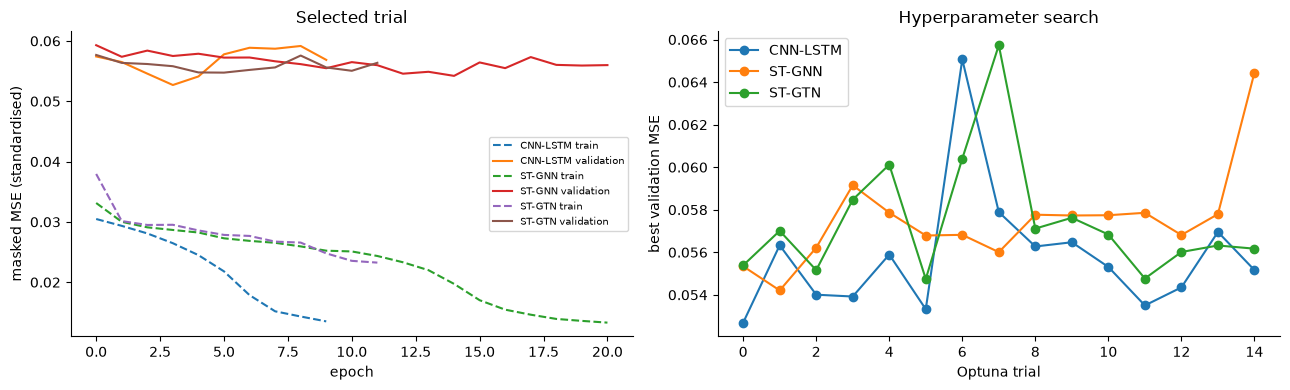

In [23]:
# Train and validation loss of the selected trial, and the validation error of every Optuna trial.
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, b_ in BEST.items():
    h_ = np.array(b_["hist"])
    ax[0].plot(h_[:, 0], "--", label=f"{name} train"); ax[0].plot(h_[:, 1], "-", label=f"{name} validation")
    ax[1].plot([t.value for t in STUDIES[name].trials if t.value is not None], "o-", label=name)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("masked MSE (standardised)"); ax[0].legend(fontsize=7); ax[0].set_title("Selected trial")
ax[1].set_xlabel("Optuna trial"); ax[1].set_ylabel("best validation MSE"); ax[1].legend(); ax[1].set_title("Hyperparameter search")
plt.tight_layout(); plt.show()

## Evaluation and the 2018 forecast

**One-step-ahead (2017).** Each 2017 map is predicted from the kriged maps of the previous L periods. The baseline is persistence, which predicts that the next map equals the last one.

**Recursive (2018).** Starting from the end of 2017, the models predict the 23 periods of 2018 one after the other, using their own forecasts as the water-table input and the observed 2018 covariates. The baselines are persistence of the last 2017 map and the seasonal climatology, the mean map of the same period over 2010 to 2016.

Two references are used for scoring:

- the kriged maps (all AOI cells), which are themselves estimates with a leave-well-out RMSE given in Section 5;
- the well readings that fall inside the grid (2017: about 70 wells; 2018: the wells reporting in 2018). These are real observations, and no 2018 reading enters the 2018 forecast.

The metrics are RMSE, MAE, NSE, MARE, SMAPE, PBIAS and R², all in metres.

In [24]:
# How many patches cover each cell, so overlapping predictions are averaged with equal weight.
WEIGHT = np.zeros((GH, GW), np.float32)
for r, c in PATCHES:
    WEIGHT[r:r + PS, c:c + PS] += 1


# One-step map from the true history, scaled from the standardised water-table channel back to metres.
@torch.no_grad()
def predict_map(model, cube, t):
    out = np.zeros((GH, GW), np.float32)
    xs = torch.from_numpy(np.stack([cube[t - L:t, :, r:r + PS, c:c + PS] for r, c in PATCHES]))
    for i in range(0, len(PATCHES), 8):
        pr = model(xs[i:i + 8].to(DEVICE)).cpu().numpy()
        for j, (r, c) in enumerate(PATCHES[i:i + 8]):
            out[r:r + PS, c:c + PS] += pr[j]
    z = out / np.maximum(WEIGHT, 1)
    return np.where(INSIDE, z * WT_SD + WT_MU, np.nan)


# Write each predicted map back into the cube, so the next period sees the forecast rather than the truth.
def recursive(model, times):
    cube = XN.copy(); maps = []
    for t in times:
        m_ = predict_map(model, cube, t)
        cube[t, 0] = np.where(INSIDE, (np.nan_to_num(m_) - WT_MU) / WT_SD, 0.0)
        maps.append(m_)
    return np.stack(maps)


# 2015-2016 and 2017 are one-step. The 2018 run is recursive. Persistence and the seasonal mean are the baselines.
t0 = time.time()
PRED = {"val": {}, "test": {}, "forecast": {}}
for name, b_ in BEST.items():
    PRED["val"][name] = np.stack([predict_map(b_["model"], XN, t) for t in SPLIT["val"]])
    PRED["test"][name] = np.stack([predict_map(b_["model"], XN, t) for t in SPLIT["test"]])
    PRED["forecast"][name] = recursive(b_["model"], SPLIT["forecast"])
PRED["val"]["Persistence"] = WT_TRUE[SPLIT["val"] - 1]
PRED["test"]["Persistence"] = WT_TRUE[SPLIT["test"] - 1]
PRED["forecast"]["Persistence"] = np.repeat(WT_TRUE[SPLIT["forecast"][0] - 1][None], len(SPLIT["forecast"]), 0)
clim_maps = np.stack([np.nanmean(WT_TRUE[(year_of <= 2016) & (np.arange(T2) % NPER == p)], 0) for p in range(NPER)])
PRED["forecast"]["Seasonal climatology"] = clim_maps
print(f"predictions in {time.time() - t0:.0f} s")

# well cells inside the grid
wr = ((GY1 - wells.y.values) // 1000).astype(int); wc = ((wells.x.values - GX0) // 1000).astype(int)
win = (wr >= 0) & (wr < GH) & (wc >= 0) & (wc < GW)
win[win] &= INSIDE[wr[win], wc[win]]
t_full = 230 + np.arange(T2)                     # index of 2010-2018 periods in the 2000-2018 panel
# Score every map against the kriged grid and against the well readings that fall in a grid cell.
rows_ = []
for split in ["test", "forecast"]:
    tt_ = SPLIT[split]
    ref_map = WT_TRUE[tt_]
    ref_w = Z[np.ix_(np.flatnonzero(win), t_full[tt_])]
    for name, pm in PRED[split].items():
        rows_.append({"split": "2017 one-step" if split == "test" else "2018 recursive", "model": name,
                      "reference": "kriged maps", **metrics(ref_map.ravel(), pm.ravel())})
        pw = pm[:, wr[win], wc[win]].T
        rows_.append({"split": "2017 one-step" if split == "test" else "2018 recursive", "model": name,
                      "reference": "well readings", **metrics(ref_w.ravel(), pw.ravel())})
RES = pd.DataFrame(rows_).set_index(["split", "reference", "model"])
print("RUN MODE:", "FULL" if FULL_RUN else "PIPELINE CHECK with synthetic covariates (not forecasts)")
RES.round(3)

predictions in 13 s
RUN MODE: FULL


n   RMSE    MAE  \
split          reference     model                                        
2017 one-step  kriged maps   CNN-LSTM              419152  1.437  1.135   
               well readings CNN-LSTM                1289  1.512  1.097   
               kriged maps   ST-GNN                419152  1.400  1.113   
               well readings ST-GNN                  1289  1.507  1.106   
               kriged maps   ST-GTN                419152  1.426  1.126   
               well readings ST-GTN                  1289  1.500  1.089   
               kriged maps   Persistence           419152  1.445  1.087   
               well readings Persistence             1289  1.488  1.060   
2018 recursive kriged maps   CNN-LSTM              419152  1.568  1.180   
               well readings CNN-LSTM                4765  2.430  1.699   
               kriged maps   ST-GNN                419152  2.105  1.705   
               well readings ST-GNN                  4765  2.956  2.233   
               kriged maps   ST-GTN                419152  1.585  1.196   
               well readings ST-GTN                  4765  2.468  1.777   
               kriged maps   Persistence           419152  1.621  1.186   
               well readings Persistence             4765  2.231  1.500   
               kriged maps   Seasonal climatology  419152  1.836  1.365   
               well readings Seasonal climatology    4765  2.761  1.838   

                                                     NSE   MARE   SMAPE  \
split          reference     model                                        
2017 one-step  kriged maps   CNN-LSTM              0.793  0.140  13.798   
               well readings CNN-LSTM              0.934  0.212  17.052   
               kriged maps   ST-GNN                0.804  0.138  13.553   
               well readings ST-GNN                0.935  0.224  17.164   
               kriged maps   ST-GTN                0.796  0.139  13.584   
               well readings ST-GTN                0.935  0.214  16.998   
               kriged maps   Persistence           0.791  0.134  13.157   
               well readings Persistence           0.936  0.210  16.720   
2018 recursive kriged maps   CNN-LSTM              0.884  0.179  15.621   
               well readings CNN-LSTM              0.844  0.257  20.295   
               kriged maps   ST-GNN                0.791  0.279  22.360   
               well readings ST-GNN                0.770  0.375  26.757   
               kriged maps   ST-GTN                0.881  0.179  16.064   
               well readings ST-GTN                0.839  0.274  21.707   
               kriged maps   Persistence           0.876  0.184  16.854   
               well readings Persistence           0.869  0.244  19.763   
               kriged maps   Seasonal climatology  0.841  0.203  17.540   
               well readings Seasonal climatology  0.799  0.278  21.514   

                                                    PBIAS     R2  
split          reference     model                                
2017 one-step  kriged maps   CNN-LSTM              -0.573  0.798  
               well readings CNN-LSTM              -0.227  0.935  
               kriged maps   ST-GNN                -0.378  0.806  
               well readings ST-GNN                -0.066  0.937  
               kriged maps   ST-GTN                -0.370  0.800  
               well readings ST-GTN                -0.260  0.936  
               kriged maps   Persistence           -0.191  0.797  
               well readings Persistence           -0.056  0.937  
2018 recursive kriged maps   CNN-LSTM               7.662  0.909  
               well readings CNN-LSTM               5.178  0.868  
               kriged maps   ST-GNN                14.789  0.872  
               well readings ST-GNN                10.973  0.828  
               kriged maps   ST-GTN                 5.090  0.891  
               well readings ST-GTN              

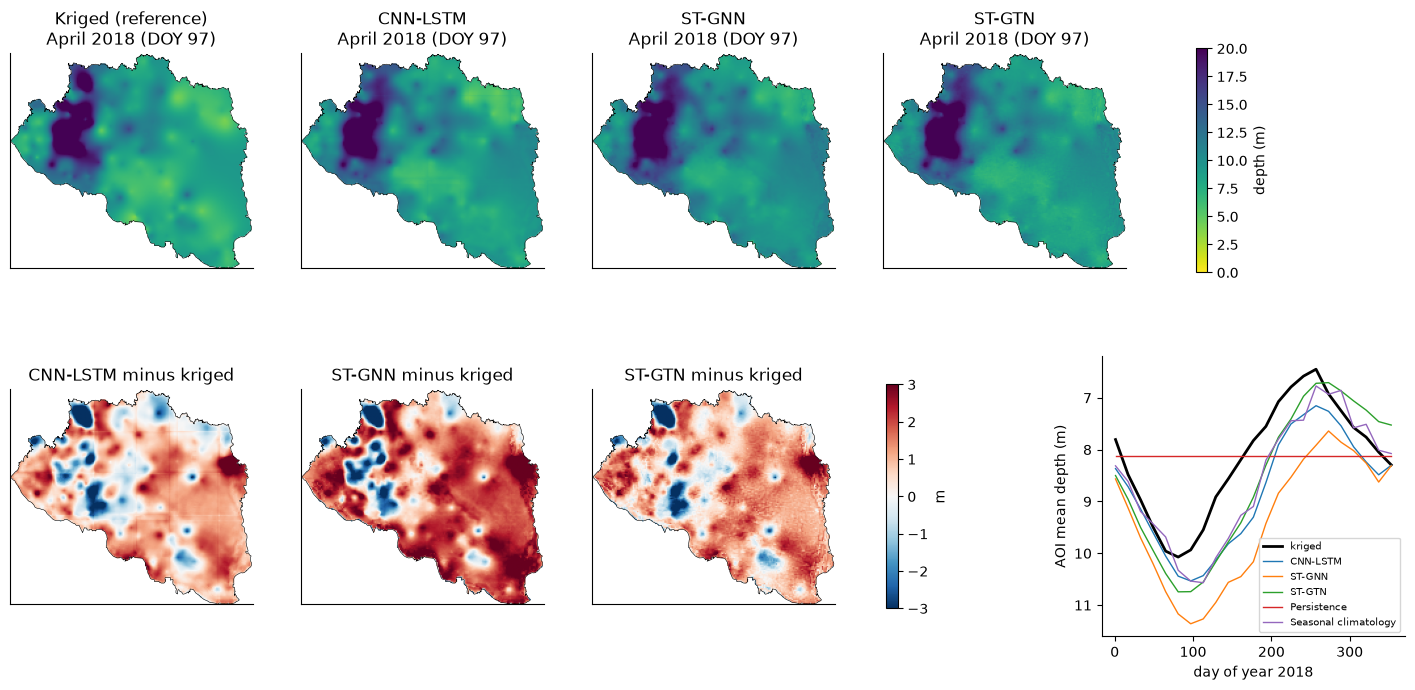

In [25]:
# April 2018 depth for the kriged map and the forecasts, then forecast minus kriged.
fig, ax = plt.subplots(2, 4, figsize=(18, 8))
p_show = 6                                       # 2018 period 7 (DOY 97, early April)
show = [("Kriged (reference)", WT_TRUE[SPLIT["forecast"][p_show]])] + \
       [(n, PRED["forecast"][n][p_show]) for n in list(BEST) + ["Seasonal climatology"]]
for a, (ttl, mp) in zip(ax[0], show[:4]):
    im = a.imshow(mp, extent=ext, cmap="viridis_r", vmin=0, vmax=20); a.set_title(f"{ttl}\nApril 2018 (DOY 97)")
    aoi.boundary.plot(ax=a, color="k", lw=0.4); a.set_xticks([]); a.set_yticks([])
plt.colorbar(im, ax=ax[0, :], shrink=0.8, label="depth (m)")
for a, (ttl, mp) in zip(ax[1, :3], show[1:4]):
    im = a.imshow(mp - show[0][1], extent=ext, cmap="RdBu_r", vmin=-3, vmax=3); a.set_title(f"{ttl} minus kriged")
    aoi.boundary.plot(ax=a, color="k", lw=0.4); a.set_xticks([]); a.set_yticks([])
plt.colorbar(im, ax=ax[1, :3], shrink=0.8, label="m")
# Area-wide mean depth through 2018 for the kriged series, the three models, and both baselines.
a = ax[1, 3]
d18 = [d for _, d in TIMES2[SPLIT["forecast"][0]:]]
a.plot(d18, np.nanmean(WT_TRUE[SPLIT["forecast"]], (1, 2)), "k-", lw=2, label="kriged")
for n in PRED["forecast"]:
    a.plot(d18, np.nanmean(PRED["forecast"][n], (1, 2)), lw=1, label=n)
a.invert_yaxis(); a.set_xlabel("day of year 2018"); a.set_ylabel("AOI mean depth (m)"); a.legend(fontsize=7)
plt.show()

## Monthly and seasonal evaluation and forecasts

The models work in 16-day periods. For planning, water levels are usually reported by month and by season. Each period is assigned to the month and season that contain its middle day (start DOY + 7), using the day-of-year buckets below.

- **Months.** The 23 periods fall 1 or 2 to a month.
- **Seasons.** Pre-monsoon runs from DOY 74 to 196 (mid-March to mid-July), monsoon from DOY 197 to 319 (mid-July to mid-November) and winter from DOY 320 to 73. Winter wraps around the new year, so a calendar year's winter combines its January to mid-March and its mid-November to December periods.

For each split, model and bucket, the period maps are averaged into one monthly or seasonal mean map per year. The mean maps are then scored against the matching kriged mean maps (all AOI cells; validation pools 2015 and 2016) and against the well readings. For the wells, the bucket mean of each well's readings is compared with the bucket mean of the prediction at that well over the same periods.

In FULL mode, the 2018 monthly and seasonal mean forecasts of the selected model (lowest validation loss) are written to `RAJ_Raster/Water_table_forecast/`, together with the kriged reference.

In [26]:
FORECASTMONTHS = 12  # Number of monthly buckets used for diagnostics/aggregation.
# Calendar months as day-of-year windows. Every month sits inside one year; winter in the season table does not.
MONTHS = {
    'January':    {'start': 1,   'end': 31,  'wraps': False},
    'February':   {'start': 32,  'end': 59,  'wraps': False},
    'March':      {'start': 60,  'end': 90,  'wraps': False},
    'April':      {'start': 91,  'end': 120, 'wraps': False},
    'May':        {'start': 121, 'end': 151, 'wraps': False},
    'June':       {'start': 152, 'end': 181, 'wraps': False},
    'July':       {'start': 182, 'end': 212, 'wraps': False},
    'August':     {'start': 213, 'end': 243, 'wraps': False},
    'September':  {'start': 244, 'end': 273, 'wraps': False},
    'October':    {'start': 274, 'end': 304, 'wraps': False},
    'November':   {'start': 305, 'end': 334, 'wraps': False},
    'December':   {'start': 335, 'end': 365, 'wraps': False},
}
FORECASTSEASONS = 3  # Number of season buckets used for diagnostics/aggregation.
SEASONS = {
    'Premonsoon': {'start': 74,  'end': 196, 'wraps': False},
    'Monsoon':    {'start': 197, 'end': 319, 'wraps': False},
    'Winter':     {'start': 320, 'end': 73,  'wraps': True},
}
SEASONORDER = ("Premonsoon", "Monsoon", "Winter")  # Fixed plotting/reporting order.
MONTHORDER = tuple(MONTHS)
assert len(MONTHS) == FORECASTMONTHS and len(SEASONS) == FORECASTSEASONS


# Inclusive day-of-year test. A wrapping bucket, used for winter, keeps both ends of the year.
def in_bucket(doy, b):
    doy = np.asarray(doy)
    return (doy >= b["start"]) | (doy <= b["end"]) if b["wraps"] else (doy >= b["start"]) & (doy <= b["end"])


def label_periods(spec, doy):
    lab = np.full(len(doy), "", dtype=object)
    for name, b in spec.items():
        lab[in_bucket(doy, b)] = name
    assert (lab != "").all(), "every period must fall in a bucket"
    return lab


# The midpoint of each 16-day period chooses its month and its season.
MID_DOY = np.array([d for _, d in TIMES2]) + 7
MONTH_OF = label_periods(MONTHS, MID_DOY)
SEASON_OF = label_periods(SEASONS, MID_DOY)
print(pd.DataFrame({"start DOY": DOYS, "mid DOY": MID_DOY[:NPER], "month": MONTH_OF[:NPER],
                    "season": SEASON_OF[:NPER]}).T.to_string(header=False))
print("\nperiods per season:", pd.Series(SEASON_OF[:NPER]).value_counts().reindex(SEASONORDER).to_dict())

start DOY        1       17        33        49      65          81          97         113         129         145         161         177      193      209      225        241        257      273      289       305       321       337       353
mid DOY          8       24        40        56      72          88         104         120         136         152         168         184      200      216      232        248        264      280      296       312       328       344       360
month      January  January  February  February   March       March       April       April         May        June        June        July     July   August   August  September  September  October  October  November  November  December  December
season      Winter   Winter    Winter    Winter  Winter  Premonsoon  Premonsoon  Premonsoon  Premonsoon  Premonsoon  Premonsoon  Premonsoon  Monsoon  Monsoon  Monsoon    Monsoon    Monsoon  Monsoon  Monsoon   Monsoon    Winter    Winter    Winter

periods per

In [27]:
# Average the periods inside a month or a season before scoring, and do that separately in each year.
WELL_ROWS = np.flatnonzero(win)
WR, WC = wr[win], wc[win]


# Map scores use the bucket-mean grid. Well scores use the mean of the readings in that bucket.
def bucket_scores(split, labels, order):
    tt = SPLIT[split]
    lab, yrs = labels[tt], year_of[tt]
    rows, means = [], {}
    for name, pm in PRED[split].items():
        for b in order:
            ref_m, pr_m, ref_w, pr_w, n_per = [], [], [], [], 0
            for y in np.unique(yrs):
                k = (lab == b) & (yrs == y)
                if not k.any():
                    continue
                n_per += k.sum()
                rm, pmm = np.nanmean(WT_TRUE[tt[k]], 0), np.nanmean(pm[k], 0)
                ref_m.append(rm.ravel()); pr_m.append(pmm.ravel())
                means[(name, b, int(y))] = pmm
                obs_w = Z[np.ix_(WELL_ROWS, t_full[tt[k]])]                 # wells x periods
                prd_w = pm[k][:, WR, WC].T
                prd_w = np.where(np.isfinite(obs_w), prd_w, np.nan)
                ref_w.append(np.nanmean(obs_w, 1)); pr_w.append(np.nanmean(prd_w, 1))
            if n_per == 0:
                continue
            base = {"split": split, "bucket": b, "model": name, "periods": n_per}
            rows.append({**base, "reference": "kriged maps", **metrics(np.concatenate(ref_m), np.concatenate(pr_m))})
            rows.append({**base, "reference": "well readings", **metrics(np.concatenate(ref_w), np.concatenate(pr_w))})
    return pd.DataFrame(rows), means


# Validation, 2017, and the 2018 forecast. The printed table is seasonal RMSE against the kriged maps.
MON, SEA, MEANS = [], [], {}
for split in ["val", "test", "forecast"]:
    m_, _ = bucket_scores(split, MONTH_OF, MONTHORDER); MON.append(m_)
    s_, mm = bucket_scores(split, SEASON_OF, SEASONORDER); SEA.append(s_)
    if split == "forecast":
        MEANS = mm
MON, SEA = pd.concat(MON, ignore_index=True), pd.concat(SEA, ignore_index=True)
SPLIT_NAME = {"val": "Validation 2015-16", "test": "Testing 2017", "forecast": "Forecast 2018"}
print("RUN MODE:", "FULL" if FULL_RUN else "PIPELINE CHECK with synthetic covariates (not forecasts)")
print("\nSeasonal scores against the kriged maps (RMSE, m):")
print(SEA[SEA.reference == "kriged maps"].pivot_table(index=["split", "model"], columns="bucket", values="RMSE")
      .reindex(columns=list(SEASONORDER)).rename(index=SPLIT_NAME).round(3).to_string())
SEA.set_index(["split", "reference", "bucket", "model"]).drop(columns="periods").round(3)

RUN MODE: FULL

Seasonal scores against the kriged maps (RMSE, m):
bucket                                   Premonsoon  Monsoon  Winter
split              model                                            
Forecast 2018      CNN-LSTM                   1.574    1.618   0.947
                   Persistence                1.403    1.722   0.864
                   ST-GNN                     2.358    2.208   1.117
                   ST-GTN                     1.566    1.576   0.887
                   Seasonal climatology       1.996    1.739   1.475
Testing 2017       CNN-LSTM                   0.171    0.269   0.203
                   Persistence                0.160    0.332   0.382
                   ST-GNN                     0.151    0.274   0.240
                   ST-GTN                     0.179    0.264   0.189
Validation 2015-16 CNN-LSTM                   0.261    0.155   0.376
                   Persistence                0.216    0.179   0.271
                   ST-GNN           

n   RMSE    MAE  \
split    reference     bucket     model                                       
val      kriged maps   Premonsoon CNN-LSTM              36448  0.261  0.207   
         well readings Premonsoon CNN-LSTM                276  0.801  0.519   
         kriged maps   Monsoon    CNN-LSTM              36448  0.155  0.121   
         well readings Monsoon    CNN-LSTM                274  0.851  0.526   
         kriged maps   Winter     CNN-LSTM              36448  0.376  0.309   
...                                                       ...    ...    ...   
forecast well readings Premonsoon Seasonal climatology    212  2.698  1.951   
         kriged maps   Monsoon    Seasonal climatology  18224  1.739  1.296   
         well readings Monsoon    Seasonal climatology    215  2.778  1.761   
         kriged maps   Winter     Seasonal climatology  18224  1.475  1.066   
         well readings Winter     Seasonal climatology    217  2.360  1.541   

                                                          NSE   MARE   SMAPE  \
split    reference     bucket     model                                        
val      kriged maps   Premonsoon CNN-LSTM              0.994  0.022   2.195   
         well readings Premonsoon CNN-LSTM              0.978  0.052   4.977   
         kriged maps   Monsoon    CNN-LSTM              0.998  0.020   1.980   
         well readings Monsoon    CNN-LSTM              0.979  0.077   7.380   
         kriged maps   Winter     CNN-LSTM              0.987  0.038   3.749   
...                                                       ...    ...     ...   
forecast well readings Premonsoon Seasonal climatology  0.786  0.263  20.745   
         kriged maps   Monsoon    Seasonal climatology  0.856  0.225  19.419   
         well readings Monsoon    Seasonal climatology  0.803  0.298  23.044   
         kriged maps   Winter     Seasonal climatology  0.883  0.131  12.319   
         well readings Winter     Seasonal climatology  0.832  0.178  16.057   

                                                        PBIAS     R2  
split    reference     bucket     model                               
val      kriged maps   Premonsoon CNN-LSTM             -1.527  0.997  
         well readings Premonsoon CNN-LSTM              0.460  0.983  
         kriged maps   Monsoon    CNN-LSTM             -0.315  0.998  
         well readings Monsoon    CNN-LSTM             -0.155  0.985  
         kriged maps   Winter     CNN-LSTM              3.592  0.996  
...                                                       ...    ...  
forecast well readings Premonsoon Seasonal climatology  6.504  0.866  
         kriged maps   Monsoon    Seasonal climatology  5.017  0.921  
         well readings Monsoon    Seasonal climatology -1.122  0.890  
         kriged maps   Winter     Seasonal climatology  0.036  0.924  
         well readings Winter     Seasonal climatology -1.826  0.901  

[78 rows x 8 columns]

Monthly scores against the kriged maps (RMSE, m):
bucket                                   January  February  March  April   May  June  July  August  September  October  November  December
split              model                                                                                                                  
Forecast 2018      CNN-LSTM                 0.53      1.05   1.40   1.53  1.71  1.82  1.87    1.71       1.75     1.60      1.65      1.62
                   Persistence              0.38      1.50   2.31   2.04  1.37  1.17  1.33    1.88       2.20     1.66      1.18      1.04
                   ST-GNN                   0.80      1.30   1.75   2.20  2.52  2.67  2.74    2.55       2.43     1.96      1.80      1.69
                   ST-GTN                   0.69      1.15   1.47   1.58  1.72  1.74  1.65    1.71       1.71     1.71      1.71      1.78
                   Seasonal climatology     1.47      1.59   1.85   2.01  2.15  2.12  2.05    1.92       1.79     1.

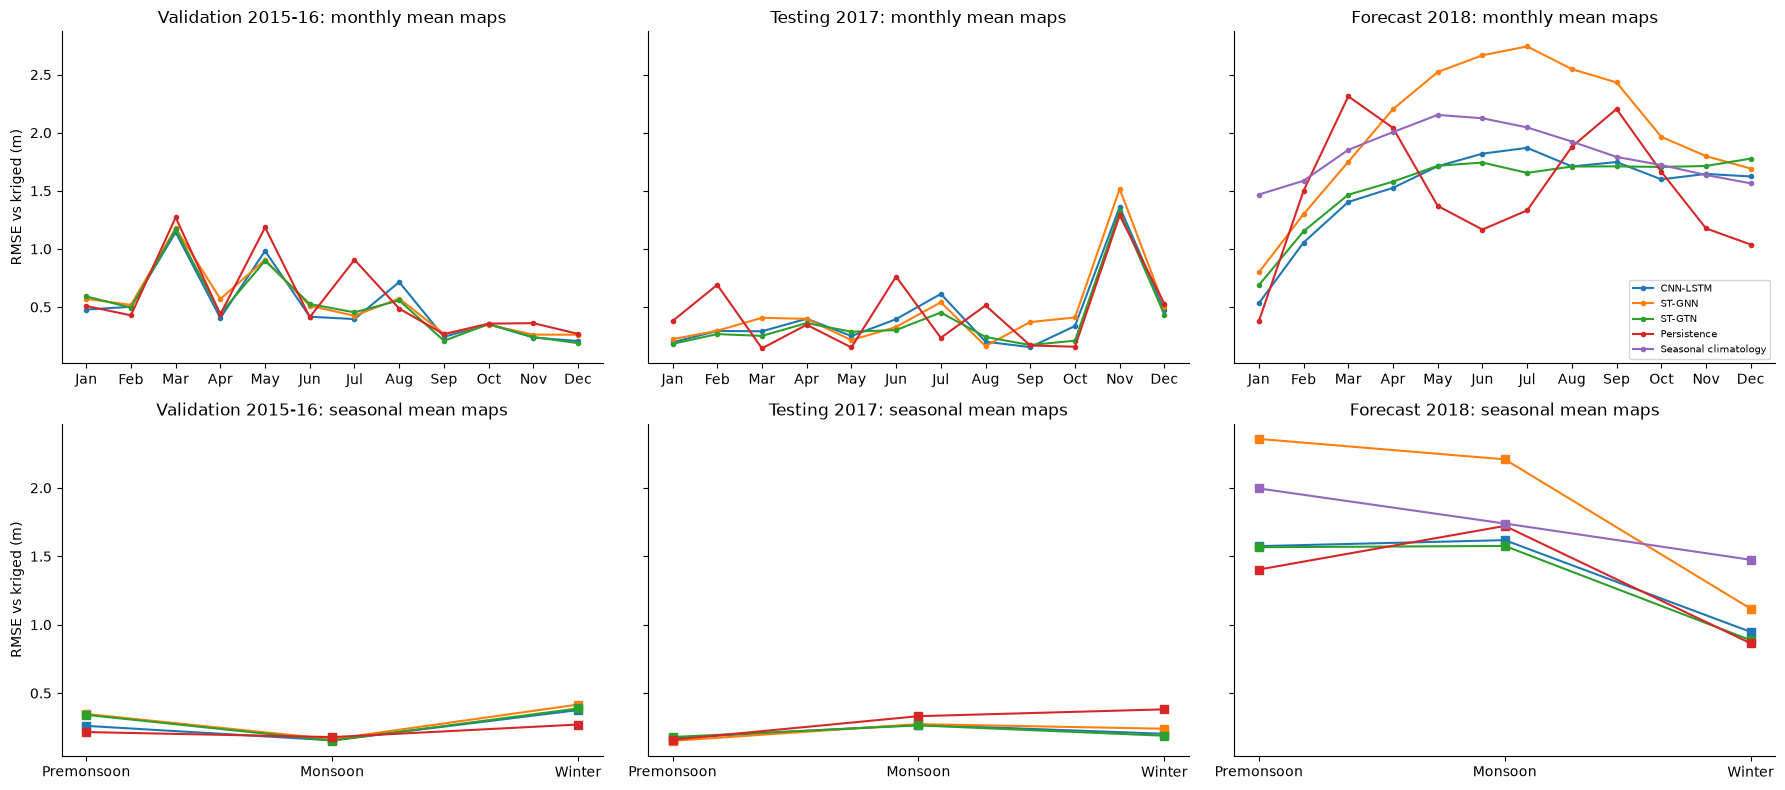

In [28]:
# Monthly RMSE against the kriged maps, and Nash-Sutcliffe score against the well readings.
print("Monthly scores against the kriged maps (RMSE, m):")
print(MON[MON.reference == "kriged maps"].pivot_table(index=["split", "model"], columns="bucket", values="RMSE")
      .reindex(columns=list(MONTHORDER)).rename(index=SPLIT_NAME).round(2).to_string())
print("\nMonthly scores against the well readings (NSE):")
print(MON[MON.reference == "well readings"].pivot_table(index=["split", "model"], columns="bucket", values="NSE")
      .reindex(columns=list(MONTHORDER)).rename(index=SPLIT_NAME).round(2).to_string())

models_all = list(PRED["forecast"])
# One column per split. Monthly RMSE on top and seasonal RMSE below, both against the kriged maps.
fig, ax = plt.subplots(2, 3, figsize=(18, 8), sharey="row")
for j, split in enumerate(["val", "test", "forecast"]):
    for name in models_all:
        d = MON[(MON.split == split) & (MON.model == name) & (MON.reference == "kriged maps")].set_index("bucket").reindex(MONTHORDER)
        if d.RMSE.notna().any():
            ax[0, j].plot(range(12), d.RMSE, "o-", ms=3, label=name)
        s = SEA[(SEA.split == split) & (SEA.model == name) & (SEA.reference == "kriged maps")].set_index("bucket").reindex(SEASONORDER)
        if s.RMSE.notna().any():
            ax[1, j].plot(range(3), s.RMSE, "s-", label=name)
    ax[0, j].set_xticks(range(12)); ax[0, j].set_xticklabels([m[:3] for m in MONTHORDER])
    ax[1, j].set_xticks(range(3)); ax[1, j].set_xticklabels(SEASONORDER)
    ax[0, j].set_title(f"{SPLIT_NAME[split]}: monthly mean maps"); ax[1, j].set_title(f"{SPLIT_NAME[split]}: seasonal mean maps")
ax[0, 0].set_ylabel("RMSE vs kriged (m)"); ax[1, 0].set_ylabel("RMSE vs kriged (m)")
ax[0, 2].legend(fontsize=7); plt.tight_layout(); plt.show()

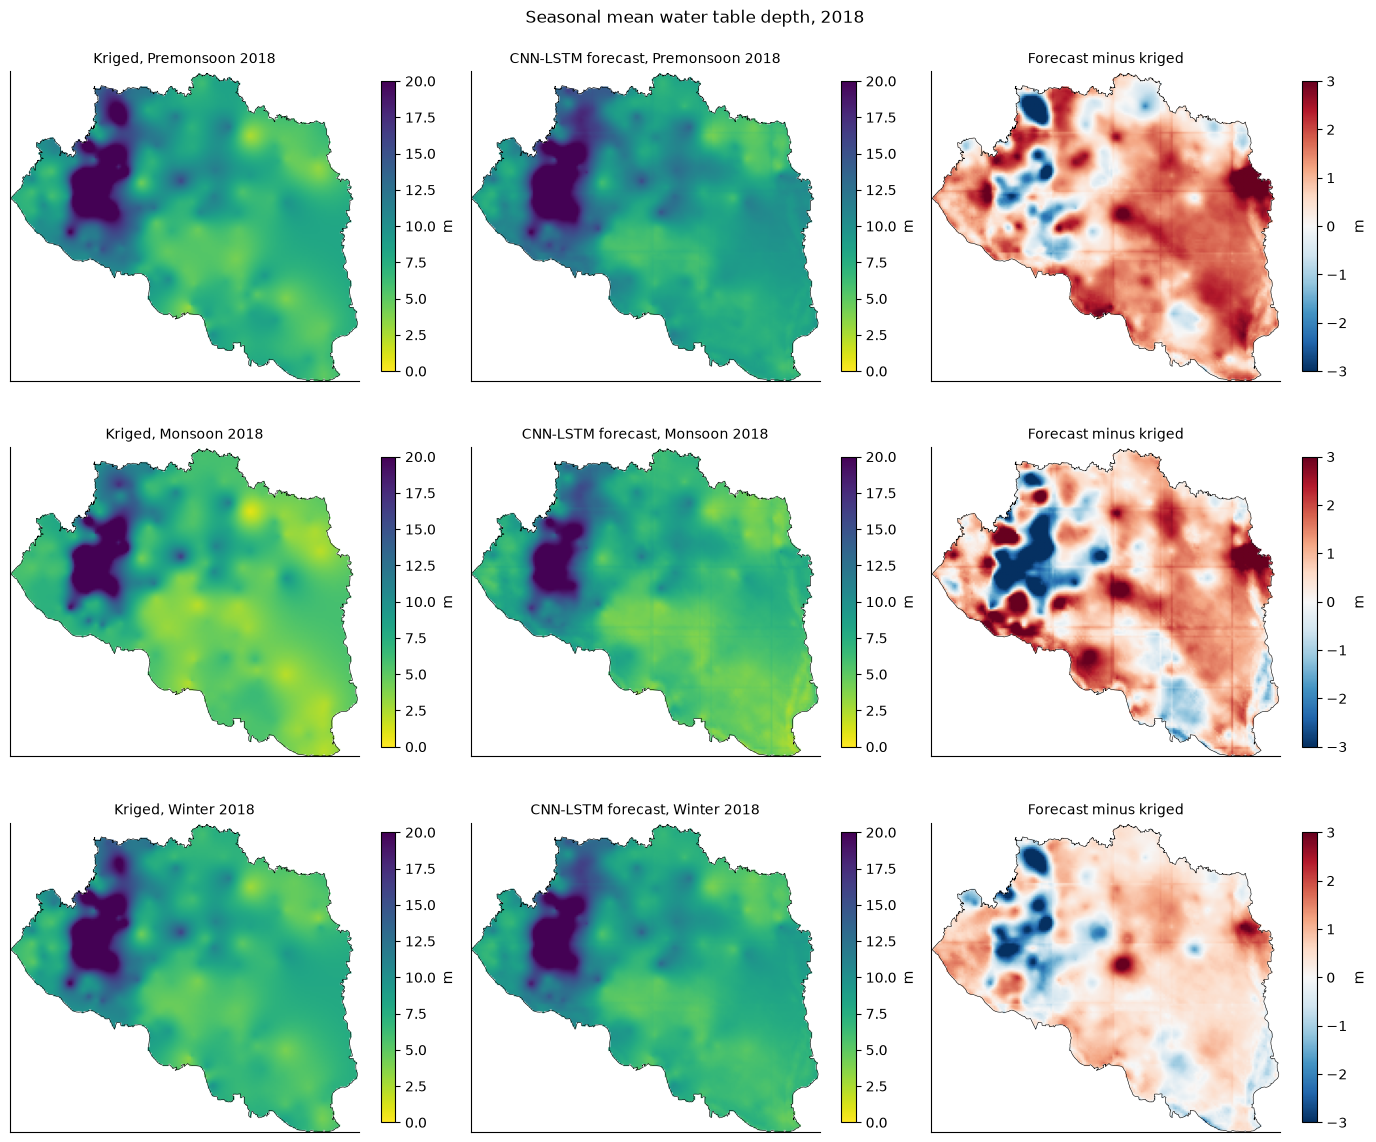

15 monthly and seasonal forecast GeoTIFFs written to Data/00_shared/data_geostatistics/BD_Raj/RAJ_Raster/Water_table_forecast


In [29]:
# Seasonal mean maps for 2018 from the model with the lowest validation loss.
BEST_NAME = min(BEST, key=lambda n: BEST[n]["val_loss"])
fig, ax = plt.subplots(3, 3, figsize=(14, 12))
tt = SPLIT["forecast"]
# Each season is a row: the kriged mean, the forecast mean, and the difference.
for i, s in enumerate(SEASONORDER):
    k = SEASON_OF[tt] == s
    ref = np.nanmean(WT_TRUE[tt[k]], 0)
    fc = MEANS[(BEST_NAME, s, 2018)]
    for j, (mp, ttl, cmap, vr) in enumerate([(ref, f"Kriged, {s} 2018", "viridis_r", (0, 20)),
                                             (fc, f"{BEST_NAME} forecast, {s} 2018", "viridis_r", (0, 20)),
                                             (fc - ref, "Forecast minus kriged", "RdBu_r", (-3, 3))]):
        im = ax[i, j].imshow(mp, extent=ext, cmap=cmap, vmin=vr[0], vmax=vr[1])
        aoi.boundary.plot(ax=ax[i, j], color="k", lw=0.4); ax[i, j].set_title(ttl, fontsize=10)
        ax[i, j].set_xticks([]); ax[i, j].set_yticks([])
        plt.colorbar(im, ax=ax[i, j], shrink=0.75, label="m")
plt.suptitle("Seasonal mean water table depth, 2018" + ("" if FULL_RUN else " (PIPELINE CHECK: synthetic covariates)"))
plt.tight_layout(); plt.show()

# Two-band GeoTIFFs, forecast and kriged reference, are written only when the covariates are real.
if FULL_RUN:
    OUT_FC = RASTER / "Water_table_forecast"; OUT_FC.mkdir(exist_ok=True)
    prof1 = dict(driver="GTiff", height=GH, width=GW, count=2, dtype="float32", crs=CRS, transform=GTR,
                 nodata=np.nan, compress="deflate", predictor=3)
    n_written = 0
    for labels, order, tag in [(MONTH_OF, MONTHORDER, "month"), (SEASON_OF, SEASONORDER, "season")]:
        for b in order:
            k = labels[tt] == b
            fc = np.nanmean(PRED["forecast"][BEST_NAME][k], 0); ref = np.nanmean(WT_TRUE[tt[k]], 0)
            with rasterio.open(OUT_FC / f"wt_forecast_2018_{tag}_{b}.tif", "w", **prof1) as d:
                d.write(np.stack([fc, ref]).astype("float32")); d.descriptions = (f"{BEST_NAME} forecast", "kriged reference")
            n_written += 1
    print(f"{n_written} monthly and seasonal forecast GeoTIFFs written to {OUT_FC.relative_to(ROOT)}")
else:
    print("PIPELINE CHECK: forecast GeoTIFFs are written only in FULL mode.")

### Monthly forecast maps, 2018

The twelve maps below are the 2018 monthly mean forecasts of the selected model, from the recursive run started at the end of 2017, so no 2018 groundwater data enter them. The second figure shows each forecast minus the kriged monthly mean map, with the month's RMSE in its title. The third compares all models and both baselines in four key months:

- January, the start of irrigation;
- April, the dry-season minimum;
- August, during monsoon recharge;
- October, near the post-monsoon maximum.

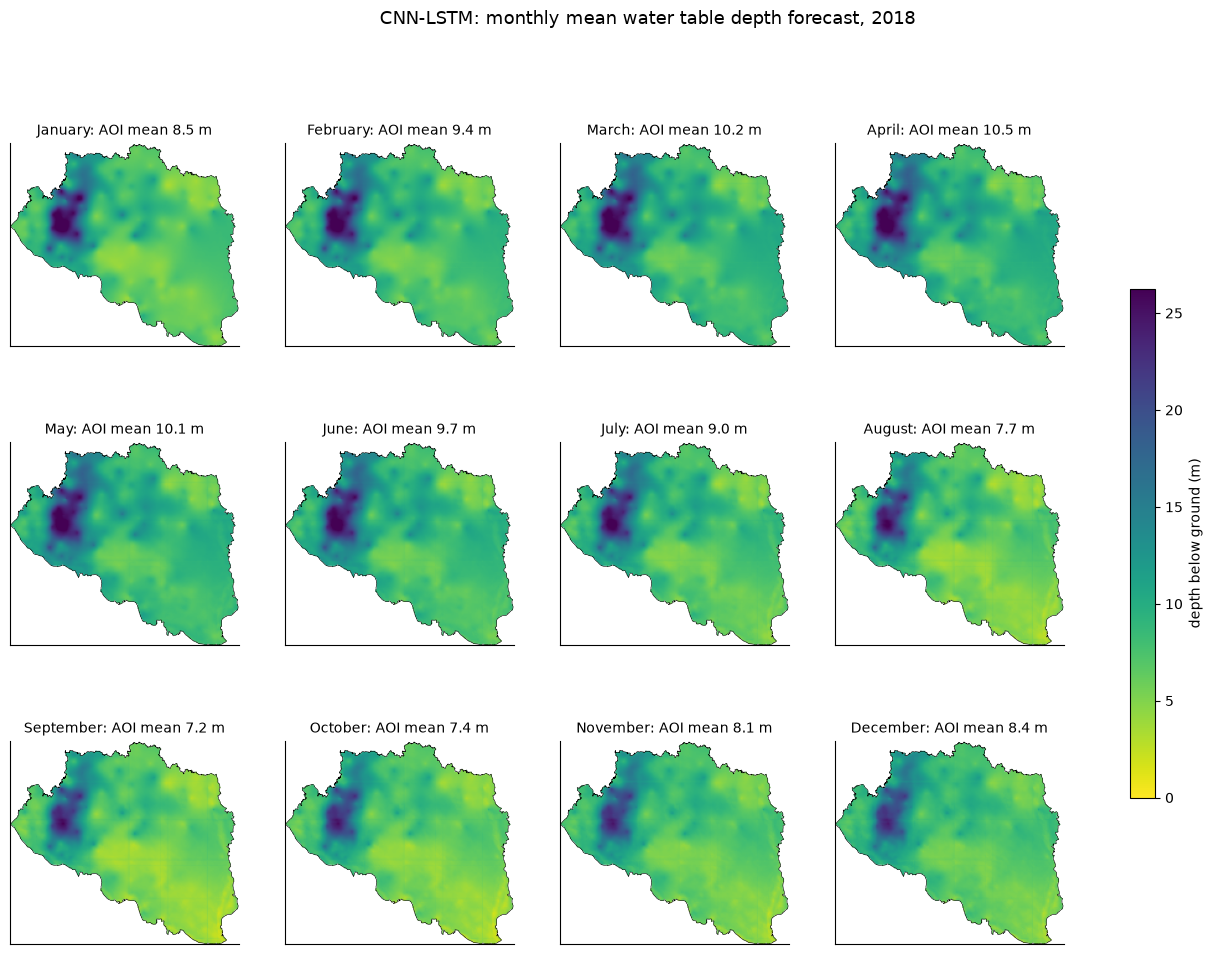

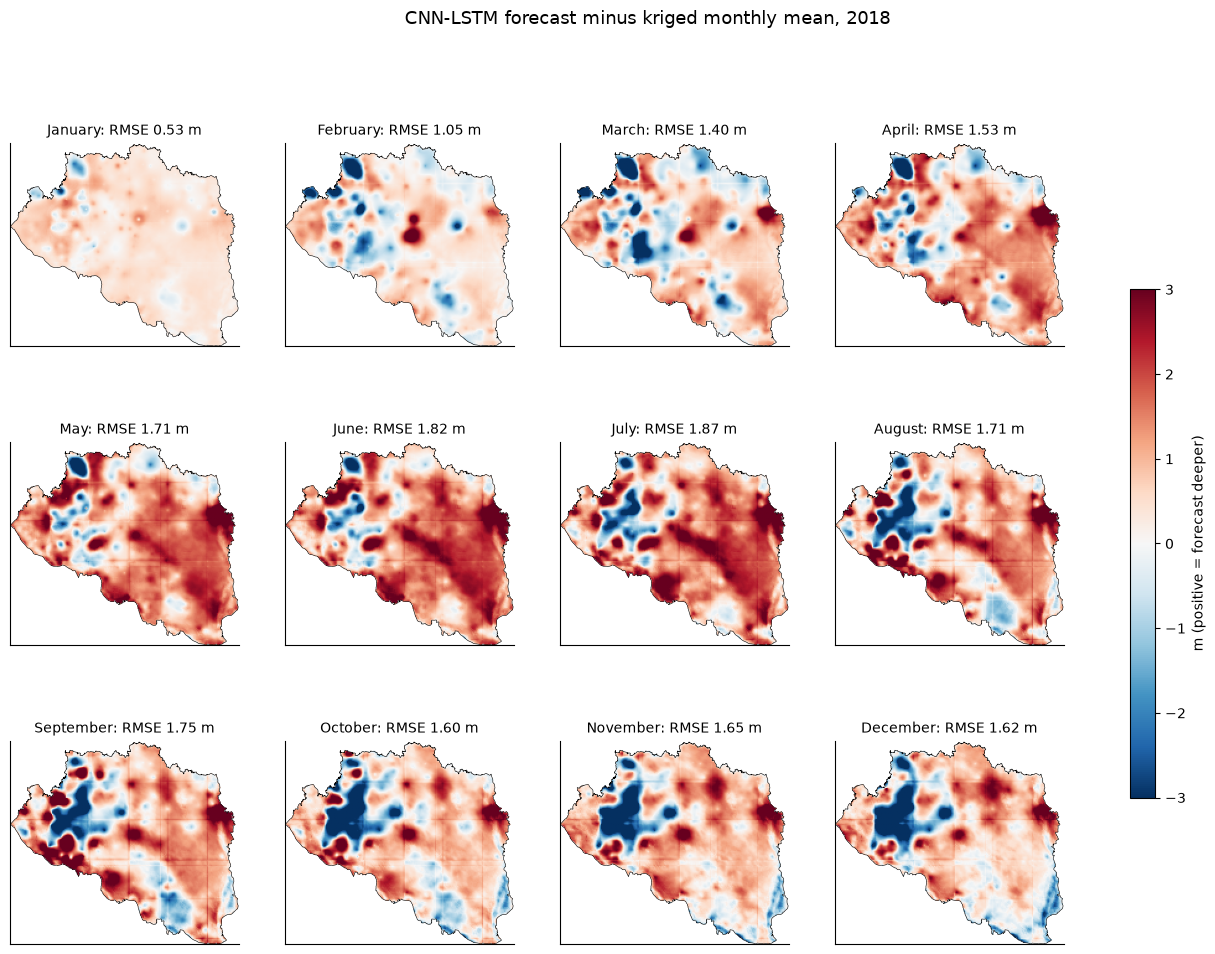

In [30]:
# Monthly mean forecast for the selected model, and the same months minus the kriged monthly mean.
tt = SPLIT["forecast"]
FC_MON = {m: np.nanmean(PRED["forecast"][BEST_NAME][MONTH_OF[tt] == m], 0) for m in MONTHORDER}
KR_MON = {m: np.nanmean(WT_TRUE[tt[MONTH_OF[tt] == m]], 0) for m in MONTHORDER}
tag = "" if FULL_RUN else "  (PIPELINE CHECK: synthetic covariates, not a forecast)"
vmax = np.nanpercentile(np.stack(list(KR_MON.values())), 99)


# Twelve panels, one per month, with the division outline and a shared colour scale.
def month_grid(maps, title, cmap, vmin, vmax_, label, subtitle=None):
    fig, ax = plt.subplots(3, 4, figsize=(17, 11))
    for a, m in zip(ax.ravel(), MONTHORDER):
        im = a.imshow(maps[m], extent=ext, cmap=cmap, vmin=vmin, vmax=vmax_)
        aoi.boundary.plot(ax=a, color="k", lw=0.4)
        a.set_title(m if subtitle is None else f"{m}: {subtitle(m)}", fontsize=10)
        a.set_xticks([]); a.set_yticks([]); a.set_xlabel(""); a.set_ylabel("")
    fig.colorbar(im, ax=ax, shrink=0.6, label=label)
    fig.suptitle(title + tag, fontsize=13)
    plt.show()


month_grid(FC_MON, f"{BEST_NAME}: monthly mean water table depth forecast, 2018", "viridis_r", 0, vmax,
           "depth below ground (m)", lambda m: f"AOI mean {np.nanmean(FC_MON[m]):.1f} m")
rmse_m = {m: np.sqrt(np.nanmean((FC_MON[m] - KR_MON[m]) ** 2)) for m in MONTHORDER}
month_grid({m: FC_MON[m] - KR_MON[m] for m in MONTHORDER}, f"{BEST_NAME} forecast minus kriged monthly mean, 2018",
           "RdBu_r", -3, 3, "m (positive = forecast deeper)", lambda m: f"RMSE {rmse_m[m]:.2f} m")

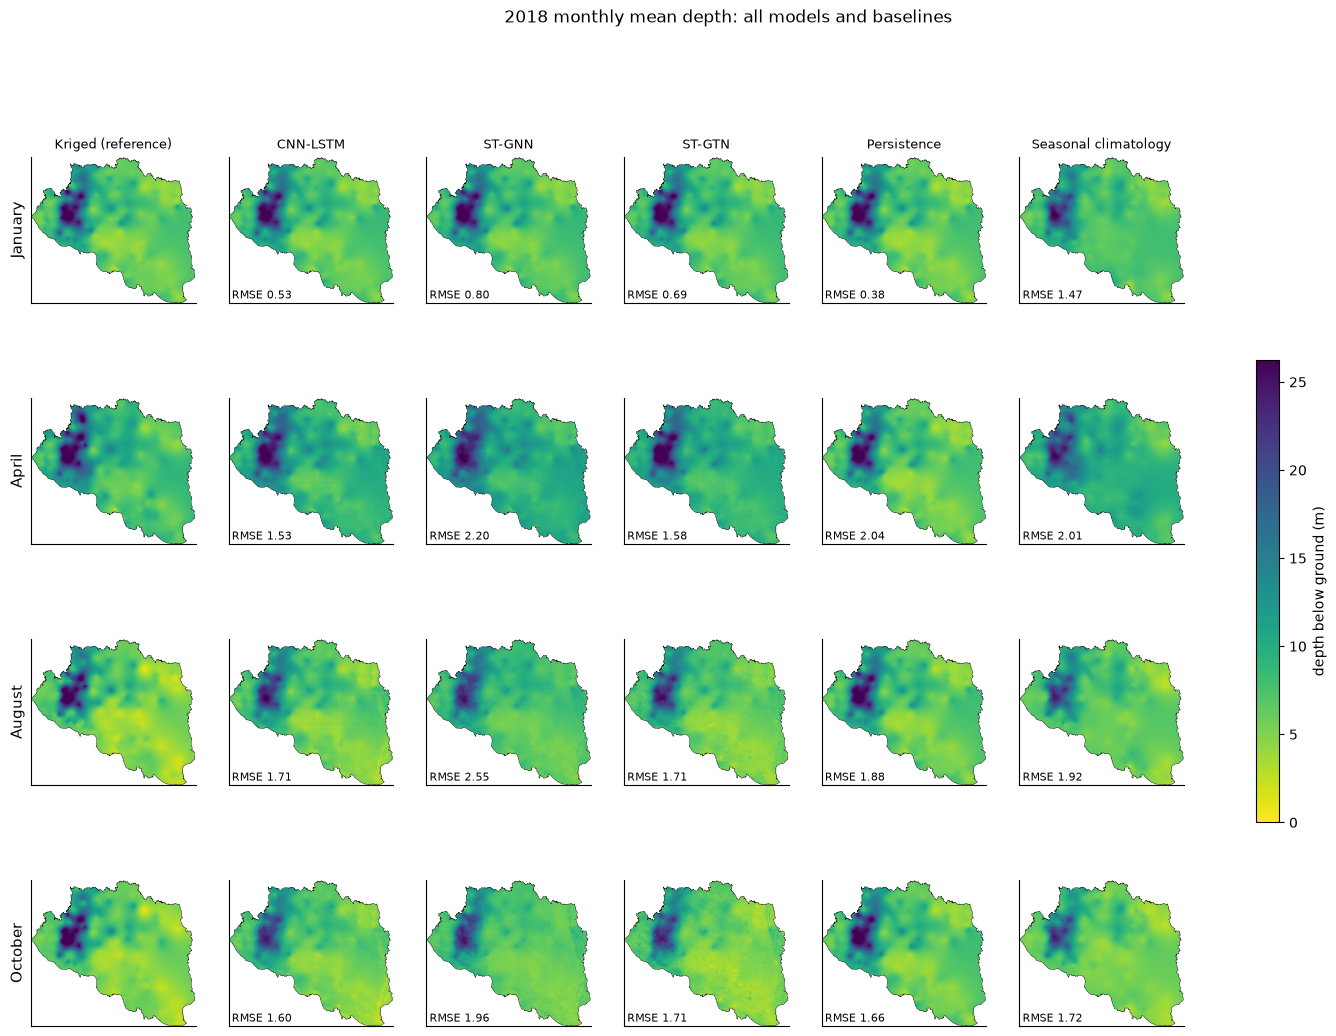

In [31]:
# January, April, August, and October for every model, against the kriged month.
key_months = ["January", "April", "August", "October"]
cols = ["Kriged (reference)"] + list(PRED["forecast"])
# Rows are those four months. Columns run from the kriged reference through each forecast, with RMSE annotated on the panel.
fig, ax = plt.subplots(len(key_months), len(cols), figsize=(3.1 * len(cols), 3.0 * len(key_months)))
for i, m in enumerate(key_months):
    k = MONTH_OF[tt] == m
    for j, c in enumerate(cols):
        mp = KR_MON[m] if j == 0 else np.nanmean(PRED["forecast"][c][k], 0)
        im = ax[i, j].imshow(mp, extent=ext, cmap="viridis_r", vmin=0, vmax=vmax)
        aoi.boundary.plot(ax=ax[i, j], color="k", lw=0.3); ax[i, j].set_xticks([]); ax[i, j].set_yticks([])
        ax[i, j].set_xlabel(""); ax[i, j].set_ylabel("")
        if i == 0:
            ax[i, j].set_title(c, fontsize=9)
        if j == 0:
            ax[i, j].set_ylabel(m, fontsize=11)
        if j > 0:
            ax[i, j].text(0.02, 0.03, f"RMSE {np.sqrt(np.nanmean((mp - KR_MON[m]) ** 2)):.2f}", transform=ax[i, j].transAxes, fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.5, label="depth below ground (m)")
fig.suptitle("2018 monthly mean depth: all models and baselines" + tag, fontsize=12)
plt.show()

**Reading the results.**

**Mode of this run.** In the version committed with these notes, the full covariate archive (about 2,100 files) was not available to the machine that executed the notebook. This section therefore ran in PIPELINE CHECK mode: real water-table cubes from Part 1, synthetic covariates and very small settings (L = 4, 2 Optuna trials, 2 epochs, 48 samples per epoch). The numbers in Sections 12 and 13 show that every step works: reading and reprojection, gap filling, cubes, Dask, normalisation, patches, graph, the three models, Optuna, early stopping and recursive forecasting, and monthly and seasonal aggregation. They say nothing about how good the models are. With 2 epochs the models have barely moved from persistence, which is exactly what the residual design should produce.

**Running it for real.** Place the covariates in `RAJ_Raster/{Climate_data, NDVI, Landuse, Population}` with the names shown in Section 7 and run the notebook again. It switches to FULL mode, writes the cubes to `RAJ_Raster/Cube_1km`, and uses L = 6, up to 40 epochs, patience 6 and 15 Optuna trials per model. On a CPU expect several hours, mostly for the ST-GTN; a GPU is used automatically if present.

**What to look for in the full run.**

- **Persistence is hard to beat one step ahead.** A 16-day change is small relative to the differences between places. A model earns its keep by having a lower RMSE and higher NSE than persistence in the 2017 one-step rows.
- **The 2018 recursive rows are the real test.** Persistence ignores the seasonal cycle, and climatology ignores the trend. A useful model should beat both over the year, especially in April (the dry-season minimum) and September (the recovery).
- **Compare the well-reading rows with the kriged-map rows.** A model can score well on the kriged maps by learning kriging's smoothness. The well rows show whether it adds anything at the points where water levels are actually measured.
- **Check PBIAS in 2018.** A recursive model that drifts shows up as a growing bias over the year.
- **Read the monthly and seasonal tables (Section 13) by season.** Averaging periods into months and seasons removes some period-to-period noise, so these errors are smaller than per-period errors. Pre-monsoon (mid-March to mid-July, the irrigation drawdown and its minimum) is where the forecast matters most for Boro rice and where persistence fails, because the water table falls quickly. In the monsoon, recharge depends on rainfall, so the climate covariates should help most there. Winter scores mix the start and the end of the calendar year.
- **The monthly tables are thin.** Each month holds only one or two 16-day periods, so a monthly score rests on one or two maps per year.

## Summary

- **The water table in Rajshahi Division is falling.** Across 260 wells, the mean depth went from 5.8 m in 2000 to about 9 m after 2010. Between 2000 to 2004 and 2014 to 2018, the 1 km maps show a dry-season decline of 2.2 m on average, over 3 m in 17% of the division and 6 to 8 m in the Barind Tract.
- **Space-time structure.** A sum-metric model with spatial and joint ranges of about 12 km (35 km practical), a temporal range of 5.5 periods and κ = 1.6 km per 16-day period fits the space-time variogram up to 128 days. A strong annual cycle beyond that is not in the model.
- **Validation.** Leaving whole wells out, space-time kriging has an RMSE of 3.0 m, NSE 0.59 and 86% coverage of the 90% interval, against 3.2 m and NSE 0.53 for IDW. Most of the remaining error is between neighbouring wells and cannot be interpolated away.
- **Outputs.** 437 five-band GeoTIFFs (mean, SD, P05, median, P95) on a 1 km BUTM 2010 grid, one per 16-day period from 2000 to 2018, and for Part 2 one multi-band cube per variable.
- **Forecasting.** CNN-LSTM, ST-GNN and ST-GTN are implemented on 64 × 64 patches and an 8-neighbour pixel graph, with Optuna tuning, early stopping and validation-based selection, and are scored per 16-day period, per month and per season (pre-monsoon, monsoon, winter) for validation (2015-16), testing (2017) and the 2018 forecast. In this run they were only checked on synthetic covariates. Their accuracy against persistence and climatology has to be judged from a full run with the real ERA-Interim, NDVI, HILDA+ and GlobPOP data.

## Limitations

- **The response of Part 2 is a kriged surface.** Away from wells the deep-learning models learn to reproduce kriging, including its smoothness and its errors. The scores against well readings are the honest ones.
- **Few wells after 2015.** Only 68 to 69 wells reported in 2016 and 2017, against more than 200 before. The validation and test maps are smoother and more uncertain than the training maps, and the split mixes a change in information with a change in time.
- **No periodic term in the variogram.** The seasonal cycle shows up as a dip in γ at 23 and 46 periods (Section 3). Within the ±4-period window used for kriging this does not matter, but a model with a cosine (hole-effect) temporal component, or kriging of anomalies from a seasonal mean, would use the previous year's readings better.
- **Covariates are not forecasts.** The 2018 run uses observed 2018 climate and NDVI. An operational forecast would need forecast or scenario climate.
- **Pumping is missing.** Irrigation abstraction drives the dry-season decline in Rajshahi. Population and cropland are weak proxies for it.

## References

- Bilonick, R. A. (1988). Monthly hydrogen ion deposition maps for the northeastern US from July 1982 to September 1984. *Atmospheric Environment*, 22(9), 1909-1924.
- Deutsch, C. V., & Journel, A. G. (1998). *GSLIB: Geostatistical Software Library and User's Guide* (2nd ed.). Oxford University Press.
- Gräler, B., Pebesma, E., & Heuvelink, G. (2016). Spatio-temporal interpolation using gstat. *The R Journal*, 8(1), 204-218.
- Kipf, T. N., & Welling, M. (2017). Semi-supervised classification with graph convolutional networks. *ICLR 2017*.
- Shi, X., Chen, Z., Wang, H., Yeung, D.-Y., Wong, W.-K., & Woo, W.-C. (2015). Convolutional LSTM network: A machine learning approach for precipitation nowcasting. *NeurIPS 28*.
- Yu, B., Yin, H., & Zhu, Z. (2018). Spatio-temporal graph convolutional networks: A deep learning framework for traffic forecasting. *IJCAI 2018*, 3634-3640.
- Dwivedi, V. P., & Bresson, X. (2021). A generalization of transformer networks to graphs. *AAAI Workshop on Deep Learning on Graphs*.
- Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. *KDD 2019*, 2623-2631.
- Dee, D. P., et al. (2011). The ERA-Interim reanalysis: configuration and performance of the data assimilation system. *Quarterly Journal of the Royal Meteorological Society*, 137, 553-597.
- Winkler, K., Fuchs, R., Rounsevell, M., & Herold, M. (2021). Global land use changes are four times greater than previously estimated. *Nature Communications*, 12, 2501.
- Liu, L., Cao, X., Li, S., & Jie, N. (2024). A 31-year (1990-2020) global gridded population dataset generated by cluster analysis and statistical learning. *Scientific Data*, 11, 124.
- Shamsudduha, M., Taylor, R. G., Ahmed, K. M., & Zahid, A. (2011). The impact of intensive groundwater abstraction on recharge to a shallow regional aquifer system: evidence from Bangladesh. *Hydrogeology Journal*, 19, 901-916.